# Proyecto Housing — Evaluación Parcial N°1 + Evaluación Parcial N°2
### MLY1101 Machine Learning — Caso B: Predicción de precios de viviendas (Ames Housing Dataset)

**Autor(es):** _[Nicolas Carrasco, Martin Corvalan, Martin Naranjo]_

Este notebook reúne en **un solo archivo** el trabajo del proyecto, separado en dos partes claramente delimitadas:

| Parte | Contenido | Secciones | Estado |
|---|---|---|---|
| **PARTE 1 — Evaluación Parcial N°1** | Comprensión del problema, definición de algoritmos, métricas y umbrales, EDA, preparación de datos, sesgos y ética | 1 a 11 | Trabajo ya realizado (se conserva **sin modificaciones**) |
| **PARTE 2 — Evaluación Parcial N°2** | Modelamiento supervisado (3 modelos), modelo no supervisado, evaluación, selección e interpretación de resultados para el negocio | 12 a 22 | Desarrollada **sobre las decisiones tomadas en la Parte 1** |

**Cómo ejecutarlo:** el notebook debe ejecutarse **de arriba hacia abajo** (la Parte 2 usa las variables que construye la Parte 1: `df_prep`, `X_train`, `X_test`, `preprocessor`, etc.). Está pensado para vivir en la carpeta `notebooks/` de un proyecto con esta estructura:

```
proyecto/
├── data/        <- Ames_Iowa_Housing_Dataset.csv (entrada) y archivos generados (housing_clean.csv, X_train.csv, ...)
├── notebooks/   <- este notebook
├── models/      <- preprocessor_pipeline.pkl y modelo_final_housing.pkl (se generan al ejecutar)
├── images/      <- gráficos exportados (se generan al ejecutar)
└── README.md    <- informe técnico en Markdown
```

> La ejecución completa toma alrededor de 5 minutos en un computador con un solo núcleo (la mayor parte corresponde al ajuste del Random Forest).


<br>

---
---
# ══════════════════════════════════════════
# PARTE 1 — EVALUACIÓN PARCIAL N°1
### Comprensión del problema · Datos · EDA · Preparación · Sesgos y ética
# ══════════════════════════════════════════
*(Contenido original de la Evaluación 1, sin modificaciones. Termina en la sección «Conclusiones y próximos pasos».)*

---
---


# Predicción de Precios de Viviendas (Ames Housing Dataset)
### Evaluación Parcial N°1 — MLY1101 Machine Learning
**Caso B: Predicción de precios de viviendas (Housing Prices)**

---

**Metodología:** CRISP-DM (Cross Industry Standard Process for Data Mining)

**Autor(es):** _[Nicolas Carrasco, Martin Corvalan, Martin Naranjo]_

**Fecha:** _[10-09-2026]_

---

## Índice
1. [Descripción del contexto / problema de negocio](#1)
2. [Objetivos del proyecto](#2)
3. [Definición inicial de criterio de salida para el/los algoritmo(s) de ML](#3)
4. [Selección inicial de algoritmo (máximo 3)](#4)
5. [Determinación y justificación de las métricas seleccionadas](#5)
6. [Criterio de Salida: umbral de métricas para considerar el modelo válido](#6)
7. [Descripción de las fuentes de datos utilizadas](#7)
8. [Análisis Exploratorio de los Datos (EDA)](#8)
9. [Preparación inicial de los Datos](#9)
10. [Análisis de Sesgos](#10)
11. [Consideraciones de Ética y Privacidad](#11)


<a id="1"></a>
## 1. Descripción del contexto / problema de negocio

Una inmobiliaria / portal de tasación necesita **estimar de forma automática y objetiva el precio de venta de una vivienda** a partir de sus características físicas, de ubicación y de calidad constructiva. Actualmente la tasación depende en gran medida del criterio de un agente o tasador, lo que genera:

- **Inconsistencia** entre tasaciones de propiedades similares.
- **Tiempos de respuesta lentos** para dar un precio de referencia a un cliente.
- **Dificultad para justificar** de manera cuantitativa el precio sugerido (qué atributos suben o bajan el valor).

El dataset utilizado es **Ames Housing Dataset** (Ames, Iowa, EE.UU.), que contiene **2.930 registros de ventas residenciales** ocurridas entre 2006 y 2010, con **82 variables** que describen aspectos como superficie, calidad de materiales, año de construcción, garage, sótano, barrio (`Neighborhood`), condiciones de venta, entre otras.


<a id="2"></a>
## 2. Objetivos del proyecto

**Objetivo general:**
> Desarrollar un modelo de Machine Learning de regresión capaz de predecir el precio de venta (`SalePrice`) de una vivienda en Ames, Iowa, a partir de sus características estructurales, de calidad y de ubicación.

**Objetivos específicos:**
1. Comprender la estructura, calidad y distribución de los datos disponibles (EDA).
2. Identificar las variables con mayor poder explicativo sobre el precio de venta.
3. Preparar y transformar los datos (limpieza, imputación, codificación, escalado) dejándolos listos para el proceso de modelamiento.
4. Evaluar posibles sesgos, aspectos éticos y de privacidad asociados al uso de estos datos.
5. Dejar una base reproducible (notebook + datos + informe) que permita, en una etapa posterior, entrenar y comparar modelos de predicción.


<a id="3"></a>
## 3. Definición inicial de criterio de salida para el/los algoritmo(s) de Machine Learning

Antes de seleccionar un algoritmo específico, se debe definir **qué tipo de problema de ML es este y qué se entenderá por "éxito"** del modelo:

- **Tipo de problema:** `SalePrice` es una variable **numérica continua**, por lo tanto este es un problema de **aprendizaje supervisado de regresión** (no de clasificación ni de clustering).
- **Criterio de salida general:** el modelo se considerará una solución viable si es capaz de **predecir el precio de venta con un error lo suficientemente bajo y consistente** como para servir de referencia confiable a un tasador o agente inmobiliario, y si dicho error **no varía de forma desproporcionada entre distintos segmentos** (por ejemplo, entre barrios de distinto nivel socioeconómico o entre viviendas de bajo y alto valor).
- En términos operativos, esto se traduce en exigir un **buen ajuste global** (medido con R²) combinado con un **error absoluto/porcentual acotado** (MAE, RMSE, MAPE), evaluados siempre sobre datos de prueba no usados en el entrenamiento, de modo de asegurar que el modelo generalice y no esté sobreajustado (*overfitting*).
- Este criterio de salida general se formaliza de manera cuantitativa en la sección 6 (Criterio de salida: umbral de métricas), una vez seleccionadas las métricas específicas en la sección 5.


<a id="4"></a>
## 4. Selección inicial de algoritmo (máximo 3)

Para un problema de regresión tabular como este, con una mezcla de variables numéricas y categóricas y ~2.900 registros, se preseleccionan los siguientes **3 algoritmos candidatos**, que serán entrenados y comparados en la etapa de modelamiento (fuera del alcance de esta evaluación):

| N° | Algoritmo | Justificación de la selección |
|---|---|---|
| 1 | **Regresión Lineal Múltiple** (con regularización Ridge/Lasso) | Modelo **base (baseline)** simple e interpretable. Permite cuantificar de forma directa el efecto de cada variable sobre el precio y sirve como punto de comparación mínimo exigible para los modelos más complejos. Funciona especialmente bien tras la transformación logarítmica de `SalePrice`, que linealiza parcialmente su relación con las variables predictoras. |
| 2 | **Random Forest Regressor** | Modelo de **ensamble basado en árboles** capaz de capturar relaciones no lineales e interacciones entre variables (ej. entre `Overall Qual` y `Neighborhood`) sin necesidad de especificarlas manualmente. Es robusto frente a outliers y variables poco relevantes, y entrega una medida de **importancia de variables** útil para la interpretabilidad del negocio. |
| 3 | **Gradient Boosting Regressor** (ej. XGBoost / LightGBM) | Suele ofrecer el **mejor desempeño predictivo** en datasets tabulares de tamaño medio como este, al construir árboles de forma secuencial que corrigen los errores de los anteriores. Se incluye como candidato de "techo de desempeño" (*performance ceiling*), a costa de una menor interpretabilidad directa que la regresión lineal. |

La comparación entre estos tres modelos permitirá evaluar el **trade-off entre interpretabilidad y desempeño predictivo**, algo especialmente relevante en un caso de uso donde el negocio (agentes/tasadores) necesita poder explicar el precio sugerido a sus clientes.


<a id="5"></a>
## 5. Determinación y justificación de las métricas seleccionadas

Dado que se trata de un problema de **regresión**, se descartan métricas de clasificación (accuracy, precision/recall, F1, AUC) y se seleccionan las siguientes métricas, cada una aportando una perspectiva distinta y complementaria del error del modelo:

| Métrica | Fórmula / Descripción | Por qué se selecciona |
|---|---|---|
| **RMSE** (Root Mean Squared Error) | Raíz del promedio de los errores al cuadrado | Está en las mismas unidades que `SalePrice` (dólares), es fácilmente interpretable para el negocio, y **penaliza más fuertemente los errores grandes**, relevante porque un error grande en la tasación de una vivienda de alto valor tiene un impacto económico significativo. |
| **MAE** (Mean Absolute Error) | Promedio del valor absoluto de los errores | Complementa al RMSE al ser **menos sensible a outliers**; representa el "error típico" esperado en dólares y es muy fácil de comunicar a un usuario de negocio ("en promedio nos equivocamos en US$ X"). |
| **R²** (Coeficiente de determinación) | Proporción de la varianza de `SalePrice` explicada por el modelo | Permite evaluar el **ajuste global** del modelo de forma estandarizada (0 a 1), independiente de la escala de precios, facilitando comparar el desempeño entre los 3 algoritmos candidatos. |
| **MAPE** (Mean Absolute Percentage Error) | Error absoluto promedio expresado como porcentaje del valor real | Es la métrica más intuitiva para el negocio inmobiliario, que suele hablar en términos porcentuales ("el modelo se equivoca en promedio un X% del valor de la vivienda"), y permite comparar el error relativo entre viviendas baratas y caras. |

No se utilizan métricas como accuracy o F1-score porque **no aplican a un problema de regresión**; tampoco se prioriza únicamente el R² porque, por sí solo, no informa la magnitud del error en términos monetarios, que es lo que finalmente le importa al negocio.


<a id="6"></a>
## 6. Criterio de Salida: umbral de métricas seleccionadas para considerar el modelo desarrollado como válido

En base a las métricas definidas en la sección 5, se establece el siguiente **umbral mínimo de aceptación** que deberá alcanzar el mejor modelo (evaluado sobre el conjunto de prueba, nunca sobre datos de entrenamiento) para considerarse una solución válida para el negocio:

| Métrica | Umbral de aceptación | Interpretación de negocio |
|---|---|---|
| **R²** | ≥ 0.80 | El modelo explica al menos el 80% de la variabilidad del precio de venta |
| **RMSE** | ≤ US$ 30.000 | El error cuadrático promedio no debe superar los US$ 30.000, aprox. un 17-19% del precio mediano (US$ 160.000) |
| **MAE** | ≤ US$ 20.000 | En promedio, el modelo no debe equivocarse en más de US$ 20.000 |
| **MAPE** | ≤ 12% | El error porcentual promedio no debe superar el 12% del valor real de la vivienda |

Si el mejor modelo entrenado **no alcanza estos umbrales**, se considerará necesario volver a etapas anteriores del proceso CRISP-DM (por ejemplo, ingeniería de variables adicional, prueba de otros algoritmos o recolección de más datos) antes de dar por válida la solución. Estos umbrales son una referencia inicial, definida con criterio de negocio, y podrán ajustarse en conjunto con los interesados (*stakeholders*) una vez obtenidos los primeros resultados de modelamiento.


<a id="7"></a>
## 7. Descripción de las fuentes de datos utilizadas

- **Fuente de datos:** `Ames_Iowa_Housing_Dataset.csv`, dataset público de viviendas vendidas en la ciudad de Ames, Iowa (EE.UU.) entre 2006 y 2010, compilado originalmente por Dean De Cock (2011) como alternativa moderna al clásico dataset de Boston Housing. Es ampliamente utilizado en la comunidad de ciencia de datos (ej. competencia *House Prices* de Kaggle).
- **Formato:** archivo CSV, 2.930 filas x 82 columnas.
- **Variable objetivo:** `SalePrice` (precio de venta en dólares).
- **Tipos de variables:** mezcla de variables numéricas (superficies, año de construcción, cantidad de baños, etc.) y categóricas (calidad de materiales, tipo de barrio, tipo de garage, etc.), además de dos columnas identificadoras (`Order`, `PID`) sin valor predictivo.
- **Herramientas y librerías utilizadas:**
  - **Python 3** como lenguaje principal.
  - **pandas / numpy** para manipulación y análisis de datos.
  - **matplotlib / seaborn** para visualización.
  - **scikit-learn** para preprocesamiento (imputación, encoding, escalado) y, en una etapa posterior, modelamiento.
  - **Jupyter Notebook** como entorno de trabajo reproducible.
  - **Git / GitHub** (o una carpeta compartida en Google Drive) como herramienta colaborativa para versionar el proyecto entre los integrantes del equipo, permitiendo trabajar en paralelo sobre el mismo notebook y dataset sin sobrescribir el trabajo de los demás.

A continuación se importan las librerías necesarias y se realiza la carga inicial del dataset.


In [1]:
# Librerías de manipulación de datos
import pandas as pd
import numpy as np

# Librerías de visualización
import matplotlib.pyplot as plt
import seaborn as sns

# Librerías de preprocesamiento (scikit-learn)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Configuración de visualización
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
pd.set_option("display.max_columns", 100)

import warnings
warnings.filterwarnings("ignore")

print("Librerías importadas correctamente.")


Librerías importadas correctamente.


In [2]:
# Carga del dataset desde la carpeta data
df = pd.read_csv("../data/Ames_Iowa_Housing_Dataset.csv")

print(f"Dimensiones del dataset: {df.shape[0]} filas x {df.shape[1]} columnas")
df.head()


Dimensiones del dataset: 2930 filas x 82 columnas


,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,Condition 1,Condition 2,Bldg Type,House Style,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Roof Style,Roof Matl,Exterior 1st,Exterior 2nd,Mas Vnr Type,Mas Vnr Area,Exter Qual,Exter Cond,Foundation,Bsmt Qual,Bsmt Cond,Bsmt Exposure,BsmtFin Type 1,BsmtFin SF 1,BsmtFin Type 2,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Heating,Heating QC,Central Air,Electrical,1st Flr SF,2nd Flr SF,Low Qual Fin SF,Gr Liv Area,Bsmt Full Bath,Bsmt Half Bath,Full Bath,Half Bath,Bedroom AbvGr,Kitchen AbvGr,Kitchen Qual,TotRms AbvGrd,Functional,Fireplaces,Fireplace Qu,Garage Type,Garage Yr Blt,Garage Finish,Garage Cars,Garage Area,Garage Qual,Garage Cond,Paved Drive,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,6,5,1960,1960,Hip,CompShg,BrkFace,Plywood,Stone,112.0,TA,TA,CBlock,TA,Gd,Gd,BLQ,639.0,Unf,0.0,441.0,1080.0,GasA,Fa,Y,SBrkr,1656,0,0,1656,1.0,0.0,1,0,3,1,TA,7,Typ,2,Gd,Attchd,1960.0,Fin,2.0,528.0,TA,TA,P,210,62,0,0,0,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Feedr,Norm,1Fam,1Story,5,6,1961,1961,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,TA,TA,CBlock,TA,TA,No,Rec,468.0,LwQ,144.0,270.0,882.0,GasA,TA,Y,SBrkr,896,0,0,896,0.0,0.0,1,0,2,1,TA,5,Typ,0,NaN,Attchd,1961.0,Unf,1.0,730.0,TA,TA,Y,140,0,0,0,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,6,6,1958,1958,Hip,CompShg,Wd Sdng,Wd Sdng,BrkFace,108.0,TA,TA,CBlock,TA,TA,No,ALQ,923.0,Unf,0.0,406.0,1329.0,GasA,TA,Y,SBrkr,1329,0,0,1329,0.0,0.0,1,1,3,1,Gd,6,Typ,0,NaN,Attchd,1958.0,Unf,1.0,312.0,TA,TA,Y,393,36,0,0,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,7,5,1968,1968,Hip,CompShg,BrkFace,BrkFace,NaN,0.0,Gd,TA,CBlock,TA,TA,No,ALQ,1065.0,Unf,0.0,1045.0,2110.0,GasA,Ex,Y,SBrkr,2110,0,0,2110,1.0,0.0,2,1,3,1,Ex,8,Typ,2,TA,Attchd,1968.0,Fin,2.0,522.0,TA,TA,Y,0,0,0,0,0,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,Gilbert,Norm,Norm,1Fam,2Story,5,5,1997,1998,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,TA,TA,PConc,Gd,TA,No,GLQ,791.0,Unf,0.0,137.0,928.0,GasA,Gd,Y,SBrkr,928,701,0,1629,0.0,0.0,2,1,3,1,TA,6,Typ,1,TA,Attchd,1997.0,Fin,2.0,482.0,TA,TA,Y,212,34,0,0,0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


In [3]:
# Tipos de datos y cantidad de valores no nulos por columna
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 2930 entries, 0 to 2929
Data columns (total 82 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Order            2930 non-null   int64  
 1   PID              2930 non-null   int64  
 2   MS SubClass      2930 non-null   int64  
 3   MS Zoning        2930 non-null   str    
 4   Lot Frontage     2440 non-null   float64
 5   Lot Area         2930 non-null   int64  
 6   Street           2930 non-null   str    
 7   Alley            198 non-null    str    
 8   Lot Shape        2930 non-null   str    
 9   Land Contour     2930 non-null   str    
 10  Utilities        2930 non-null   str    
 11  Lot Config       2930 non-null   str    
 12  Land Slope       2930 non-null   str    
 13  Neighborhood     2930 non-null   str    
 14  Condition 1      2930 non-null   str    
 15  Condition 2      2930 non-null   str    
 16  Bldg Type        2930 non-null   str    
 17  House Style      2930 non

In [4]:
# Estadísticas descriptivas de variables numéricas
df.describe().T


,count,mean,std,min,25%,50%,75%,max
Order,2930.0,1.465500e+03,8.459625e+02,1.0,7.332500e+02,1465.5,2.197750e+03,2.930000e+03
PID,2930.0,7.144645e+08,1.887308e+08,526301100.0,5.284770e+08,535453620.0,9.071811e+08,1.007100e+09
MS SubClass,2930.0,5.738737e+01,4.263802e+01,20.0,2.000000e+01,50.0,7.000000e+01,1.900000e+02
Lot Frontage,2440.0,6.922459e+01,2.336533e+01,21.0,5.800000e+01,68.0,8.000000e+01,3.130000e+02
Lot Area,2930.0,1.014792e+04,7.880018e+03,1300.0,7.440250e+03,9436.5,1.155525e+04,2.152450e+05
Overall Qual,2930.0,6.094881e+00,1.411026e+00,1.0,5.000000e+00,6.0,7.000000e+00,1.000000e+01
Overall Cond,2930.0,5.563140e+00,1.111537e+00,1.0,5.000000e+00,5.0,6.000000e+00,9.000000e+00
Year Built,2930.0,1.971356e+03,3.024536e+01,1872.0,1.954000e+03,1973.0,2.001000e+03,2.010000e+03
Year Remod/Add,2930.0,1.984267e+03,2.086029e+01,1950.0,1.965000e+03,1993.0,2.004000e+03,2.010000e+03
Mas Vnr Area,2907.0,1.018968e+02,1.791126e+02,0.0,0.000000e+00,0.0,1.640000e+02,1.600000e+03


In [5]:
# Estadísticas descriptivas de variables categóricas
df.describe(include="object").T


,count,unique,top,freq
MS Zoning,2930,7,RL,2273
Street,2930,2,Pave,2918
Alley,198,2,Grvl,120
Lot Shape,2930,4,Reg,1859
Land Contour,2930,4,Lvl,2633
Utilities,2930,3,AllPub,2927
Lot Config,2930,5,Inside,2140
Land Slope,2930,3,Gtl,2789
Neighborhood,2930,28,NAmes,443
Condition 1,2930,9,Norm,2522


**Observaciones iniciales:**
- El dataset combina **variables numéricas** con **variables categóricas**, como se anticipó.
- La variable objetivo es **`SalePrice`**.
- Las columnas `Order` y `PID` son identificadoras y se excluirán del proceso de modelamiento.


<a id="8"></a>
## 8. Análisis Exploratorio de los Datos (EDA)

En esta sección se analiza la **calidad de los datos** (valores nulos, duplicados, outliers) y se identifican **patrones y variables relevantes** relacionadas con el precio de venta.

### 8.1 Calidad de los datos: valores duplicados


In [6]:
# Verificación de filas duplicadas y de identificadores únicos (PID)
print(f"Filas totalmente duplicadas: {df.duplicated().sum()}")
print(f"Identificadores de propiedad (PID) duplicados: {df['PID'].duplicated().sum()}")


Filas totalmente duplicadas: 0
Identificadores de propiedad (PID) duplicados: 0


No se detectan filas duplicadas ni identificadores de propiedad repetidos, lo que indica que cada registro corresponde a una venta única.

### 8.2 Calidad de los datos: valores nulos (missing values)


In [7]:
# Cálculo de valores nulos por columna (cantidad y porcentaje)
nulos = df.isnull().sum()
nulos_pct = (nulos / len(df) * 100).round(2)

tabla_nulos = pd.DataFrame({
    "n_nulos": nulos,
    "pct_nulos": nulos_pct
})
tabla_nulos = tabla_nulos[tabla_nulos["n_nulos"] > 0].sort_values("pct_nulos", ascending=False)
tabla_nulos


,n_nulos,pct_nulos
Pool QC,2917,99.56
Misc Feature,2824,96.38
Alley,2732,93.24
Fence,2358,80.48
Mas Vnr Type,1775,60.58
Fireplace Qu,1422,48.53
Lot Frontage,490,16.72
Garage Qual,159,5.43
Garage Cond,159,5.43
Garage Yr Blt,159,5.43


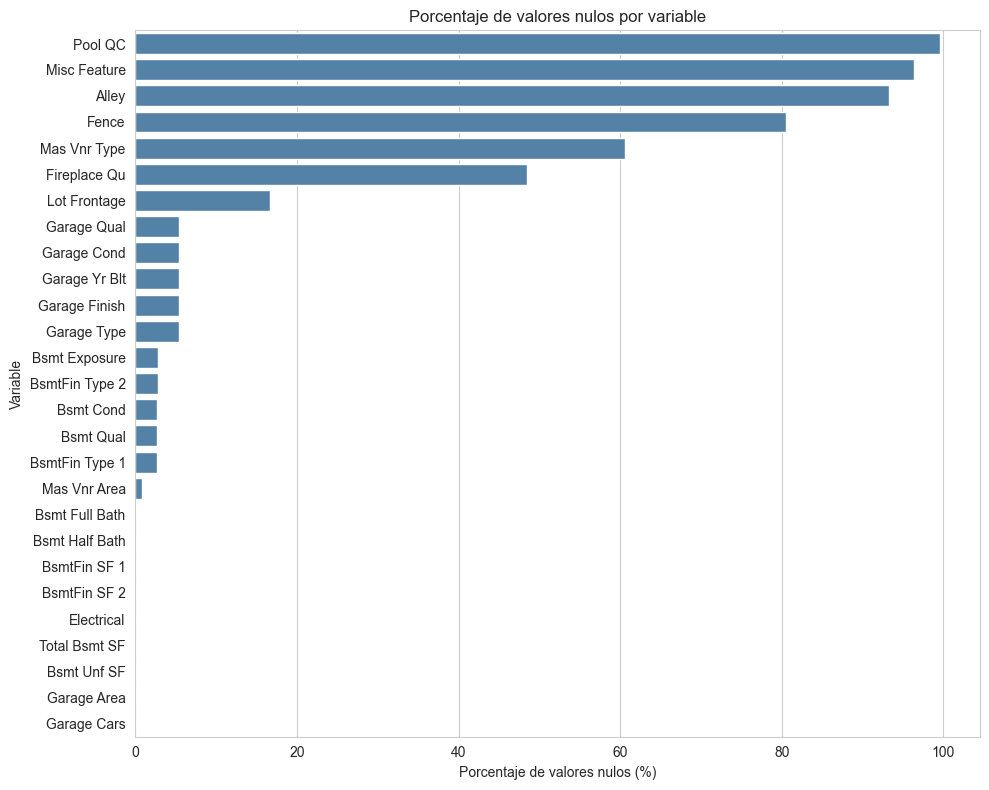

In [8]:
# Visualización de las variables con mayor porcentaje de valores nulos
plt.figure(figsize=(10, 8))
sns.barplot(x=tabla_nulos["pct_nulos"], y=tabla_nulos.index, color="steelblue")
plt.xlabel("Porcentaje de valores nulos (%)")
plt.ylabel("Variable")
plt.title("Porcentaje de valores nulos por variable")
plt.tight_layout()
plt.savefig("../images/valores_nulos.png", dpi=120)
plt.show()


**Interpretación de los valores nulos:**

Es fundamental notar que, según el diccionario de datos del Ames Housing Dataset, **la mayoría de estos "nulos" no son datos faltantes por error, sino que representan la ausencia física del atributo**. Por ejemplo:

- `Pool QC` nulo → la vivienda **no tiene piscina**.
- `Alley` nulo → la vivienda **no tiene acceso por callejón**.
- `Fence` nulo → la vivienda **no tiene cerco**.
- `Fireplace Qu` nulo → la vivienda **no tiene chimenea**.
- `Garage Type/Finish/Qual/Cond/Yr Blt` nulos → la vivienda **no tiene garage**.
- `Bsmt Qual/Cond/Exposure/BsmtFin Type 1-2` nulos → la vivienda **no tiene sótano**.

Solo un pequeño grupo de variables corresponde a **verdaderos datos faltantes** que deberán imputarse en la etapa de preparación:
- `Lot Frontage` (frontis del lote, ~16,7% de nulos): probablemente no se registró en terreno.
- `Mas Vnr Type` / `Mas Vnr Area` (revestimiento de mampostería): pocos casos, posible omisión de registro.
- `Electrical`, `Garage Cars`, `Garage Area`, `Total Bsmt SF`, `Bsmt Full/Half Bath`, `BsmtFin SF 1/2`, `Bsmt Unf SF`: 1 o 2 casos aislados, probablemente error de captura.

Esta distinción es clave: para las variables de "ausencia de atributo" se imputará el valor `"None"` (categóricas) o `0` (numéricas), mientras que para los verdaderos faltantes se usará una imputación estadística (mediana / moda). Esto se ejecuta en la sección 9.

### 8.3 Análisis de la variable objetivo: `SalePrice`


count      2930.000000
mean     180796.060068
std       79886.692357
min       12789.000000
25%      129500.000000
50%      160000.000000
75%      213500.000000
max      755000.000000
Name: SalePrice, dtype: float64


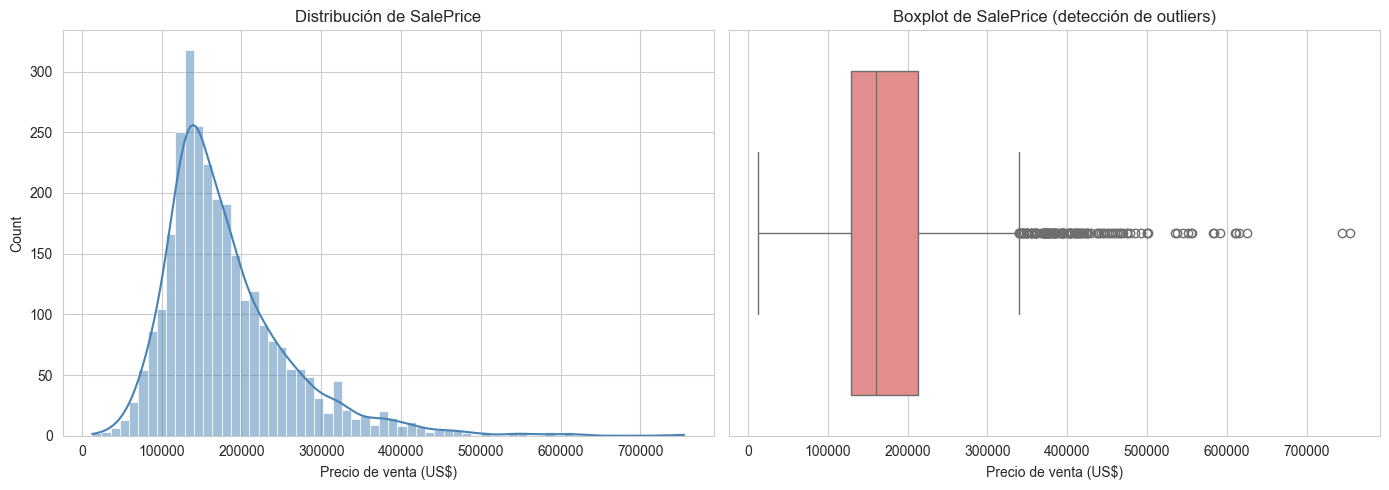

In [9]:
print(df["SalePrice"].describe())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df["SalePrice"], kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("Distribución de SalePrice")
axes[0].set_xlabel("Precio de venta (US$)")

sns.boxplot(x=df["SalePrice"], ax=axes[1], color="lightcoral")
axes[1].set_title("Boxplot de SalePrice (detección de outliers)")
axes[1].set_xlabel("Precio de venta (US$)")

plt.tight_layout()
plt.savefig("../images/distribucion_saleprice.png", dpi=120)
plt.show()


**Interpretación:**
- La variable `SalePrice` presenta una **distribución asimétrica hacia la derecha (right-skewed)**: la mayoría de las viviendas se concentran entre US$ 130.000 y US$ 215.000 (percentiles 25 y 75), pero existen algunas viviendas de muy alto valor (hasta US$ 755.000) que estiran la distribución.
- Esta asimetría sugiere que, en la etapa de modelamiento, podría ser beneficioso aplicar una **transformación logarítmica** (`log(SalePrice)`) para normalizar la distribución y mejorar el desempeño de modelos como la Regresión Lineal (candidato N°1 de la sección 4).
- El boxplot confirma la presencia de **outliers en el extremo superior** (viviendas de lujo), que deberán analizarse con cuidado: no necesariamente son errores, pueden ser casos legítimos que requieren tratamiento especial.

### 8.4 Relación entre variables numéricas y el precio de venta


In [10]:
# Matriz de correlación de variables numéricas con SalePrice
num_cols = df.select_dtypes(include=[np.number]).columns.drop(["Order", "PID"])
correlaciones = df[num_cols].corr()["SalePrice"].sort_values(ascending=False)
correlaciones


SalePrice          1.000000
Overall Qual       0.799262
Gr Liv Area        0.706780
Garage Cars        0.647877
Garage Area        0.640401
Total Bsmt SF      0.632280
1st Flr SF         0.621676
Year Built         0.558426
Full Bath          0.545604
Year Remod/Add     0.532974
Garage Yr Blt      0.526965
Mas Vnr Area       0.508285
TotRms AbvGrd      0.495474
Fireplaces         0.474558
BsmtFin SF 1       0.432914
Lot Frontage       0.357318
Wood Deck SF       0.327143
Open Porch SF      0.312951
Half Bath          0.285056
Bsmt Full Bath     0.276050
2nd Flr SF         0.269373
Lot Area           0.266549
Bsmt Unf SF        0.182855
Bedroom AbvGr      0.143913
Screen Porch       0.112151
Pool Area          0.068403
Mo Sold            0.035259
3Ssn Porch         0.032225
BsmtFin SF 2       0.005891
Misc Val          -0.015691
Yr Sold           -0.030569
Bsmt Half Bath    -0.035835
Low Qual Fin SF   -0.037660
MS SubClass       -0.085092
Overall Cond      -0.101697
Kitchen AbvGr     -0

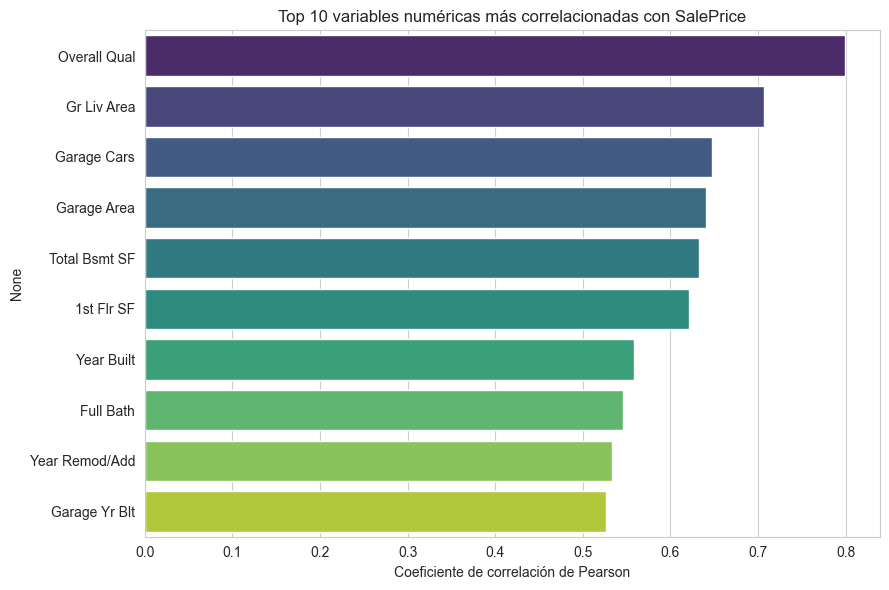

In [11]:
# Top 10 variables más correlacionadas (positiva o negativamente) con SalePrice
top_corr = correlaciones.drop("SalePrice").abs().sort_values(ascending=False).head(10).index
top_corr_valores = correlaciones[top_corr]

plt.figure(figsize=(9, 6))
sns.barplot(x=top_corr_valores.values, y=top_corr_valores.index, palette="viridis")
plt.title("Top 10 variables numéricas más correlacionadas con SalePrice")
plt.xlabel("Coeficiente de correlación de Pearson")
plt.tight_layout()
plt.savefig("../images/top_correlaciones.png", dpi=120)
plt.show()


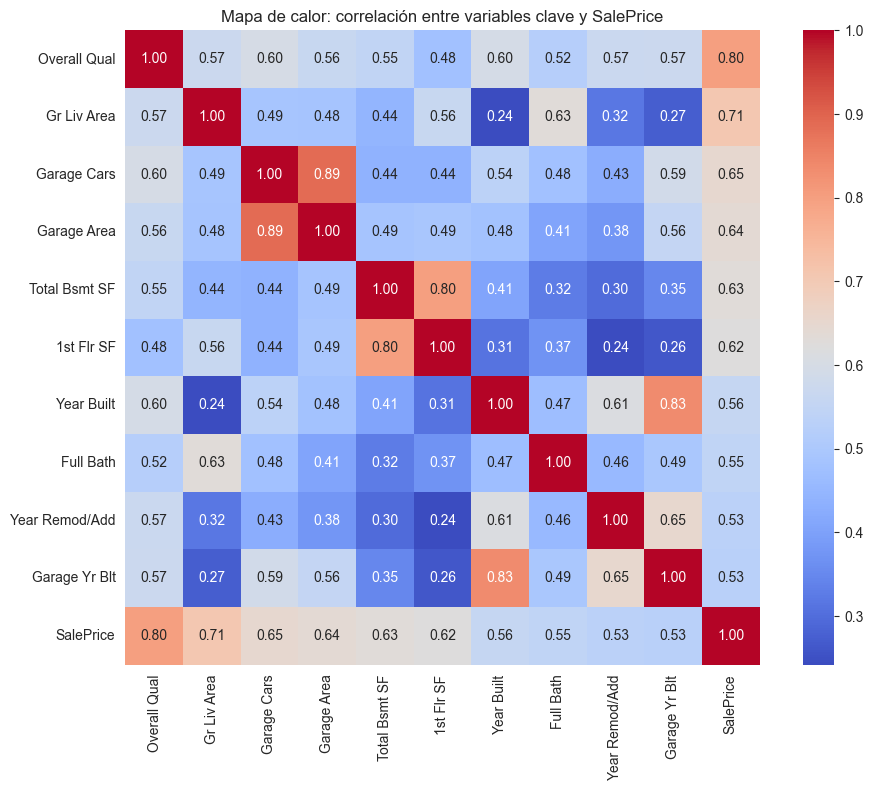

In [12]:
# Mapa de calor de correlaciones entre las variables más relevantes
top_vars = list(top_corr) + ["SalePrice"]
plt.figure(figsize=(10, 8))
sns.heatmap(df[top_vars].corr(), annot=True, fmt=".2f", cmap="coolwarm", square=True)
plt.title("Mapa de calor: correlación entre variables clave y SalePrice")
plt.tight_layout()
plt.savefig("../images/heatmap_correlaciones.png", dpi=120)
plt.show()


**Patrones identificados:**
- `Overall Qual` (calidad general de materiales y acabados) es, por lejos, la variable con **mayor correlación positiva** con el precio de venta.
- `Gr Liv Area` (superficie habitable sobre el nivel del suelo) y `Garage Cars`/`Garage Area` también muestran correlaciones altas: a mayor superficie y capacidad de garage, mayor precio.
- `Total Bsmt SF` y `1st Flr SF` (superficie del sótano y del primer piso) refuerzan la idea de que **el tamaño construido es un factor central** en el precio.
- `Year Built` y `Year Remod/Add` muestran que las viviendas más nuevas o remodeladas recientemente tienden a tener mayor valor.

### 8.5 Relación entre variables categóricas relevantes y el precio de venta


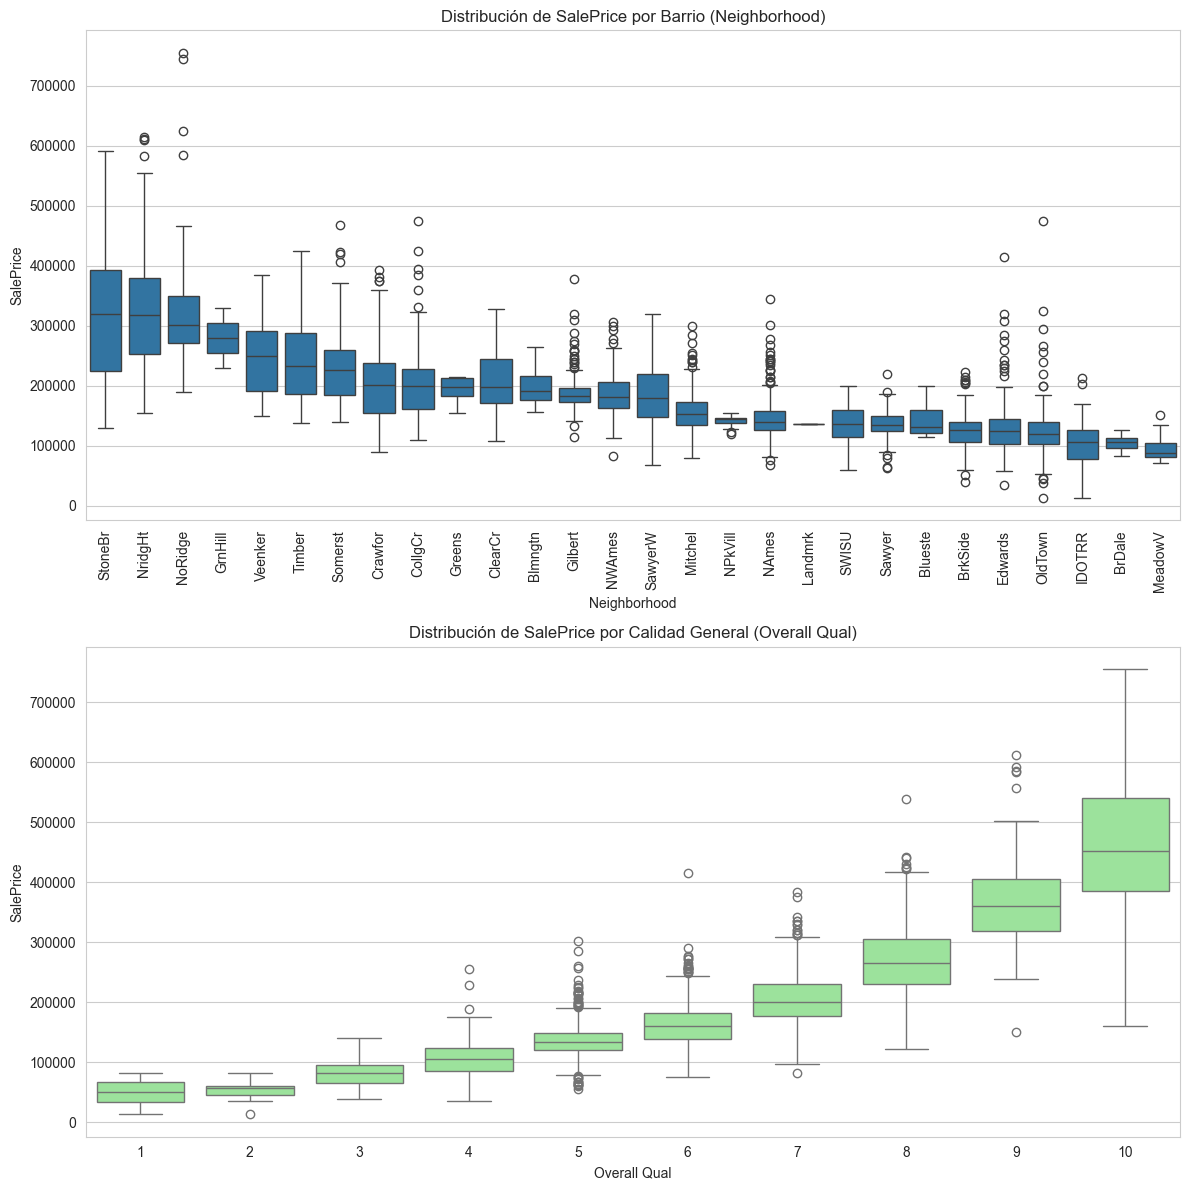

In [13]:
fig, axes = plt.subplots(2, 1, figsize=(12, 12))

# Precio promedio por barrio (Neighborhood)
orden_barrios = df.groupby("Neighborhood")["SalePrice"].median().sort_values(ascending=False).index
sns.boxplot(data=df, x="Neighborhood", y="SalePrice", order=orden_barrios, ax=axes[0])
axes[0].set_title("Distribución de SalePrice por Barrio (Neighborhood)")
axes[0].tick_params(axis="x", rotation=90)

# Precio promedio por calidad general (Overall Qual)
sns.boxplot(data=df, x="Overall Qual", y="SalePrice", ax=axes[1], color="lightgreen")
axes[1].set_title("Distribución de SalePrice por Calidad General (Overall Qual)")

plt.tight_layout()
plt.savefig("../images/saleprice_por_categoria.png", dpi=120)
plt.show()


**Interpretación:**
- Existe una **variabilidad considerable en el precio según el barrio** (`Neighborhood`): barrios como *NridgHt*, *NoRidge* o *StoneBr* concentran las viviendas más caras, mientras que otros como *MeadowV* o *IDOTRR* concentran las más económicas. Esto confirma que la **ubicación es una variable clave** a incluir en el modelo (este hallazgo se retoma en la sección 10, Análisis de Sesgos).
- Se observa una **relación monotónica clara** entre `Overall Qual` (escala 1 a 10) y `SalePrice`: a mayor calidad, mayor precio, sin excepciones relevantes.

### 8.6 Detección de outliers (variables numéricas clave)


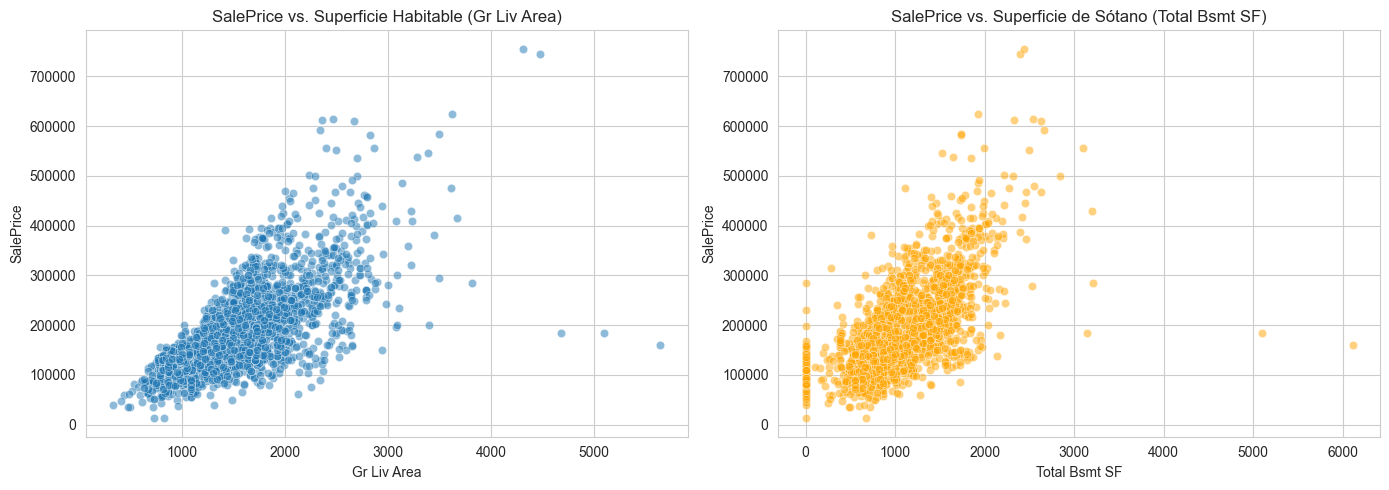

Outliers evidentes detectados (Gr Liv Area > 4000 y SalePrice < 300,000): 3


,PID,Gr Liv Area,SalePrice,Neighborhood,Sale Condition
1498,908154235,5642,160000,Edwards,Partial
2180,908154195,5095,183850,Edwards,Partial
2181,908154205,4676,184750,Edwards,Partial


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(data=df, x="Gr Liv Area", y="SalePrice", ax=axes[0], alpha=0.5)
axes[0].set_title("SalePrice vs. Superficie Habitable (Gr Liv Area)")

sns.scatterplot(data=df, x="Total Bsmt SF", y="SalePrice", ax=axes[1], alpha=0.5, color="orange")
axes[1].set_title("SalePrice vs. Superficie de Sótano (Total Bsmt SF)")

plt.tight_layout()
plt.savefig("../images/outliers_scatter.png", dpi=120)
plt.show()

# Identificación explícita de outliers evidentes: viviendas muy grandes pero muy baratas
outliers_evidentes = df[(df["Gr Liv Area"] > 4000) & (df["SalePrice"] < 300000)]
print(f"Outliers evidentes detectados (Gr Liv Area > 4000 y SalePrice < 300,000): {len(outliers_evidentes)}")
outliers_evidentes[["PID", "Gr Liv Area", "SalePrice", "Neighborhood", "Sale Condition"]]


**Interpretación:** se identifican un par de viviendas con **superficie habitable muy grande (> 4.000 pies²) pero precio de venta bajo**, un patrón atípico que rompe la relación esperada tamaño-precio. Estos casos suelen corresponder a ventas con condiciones especiales (`Sale Condition` distinto de `Normal`, por ejemplo ventas entre familiares o liquidaciones) y son candidatos a **eliminarse o tratarse por separado** en la etapa de modelamiento, ya que podrían distorsionar el ajuste del modelo.

### 8.7 Resumen de hallazgos del EDA

| Hallazgo | Implicancia para la preparación de datos |
|---|---|
| Distribución asimétrica de `SalePrice` | Evaluar transformación logarítmica |
| Nulos "estructurales" (Pool, Garage, Bsmt, etc.) | Imputar como `"None"` / `0`, no eliminar filas |
| Nulos reales aislados (`Lot Frontage`, `Electrical`, etc.) | Imputar con mediana (numéricas) / moda (categóricas) |
| `Overall Qual`, `Gr Liv Area`, `Garage Cars/Area` fuertemente correlacionados con el precio | Priorizar como variables predictoras |
| `Neighborhood` con fuerte efecto sobre el precio | Codificar (One-Hot Encoding) e incluir en el modelo |
| Outliers de viviendas grandes y baratas | Evaluar exclusión o tratamiento robusto en modelamiento |
| Columnas `Order` y `PID` son identificadores | Excluir del set de variables predictoras |


<a id="9"></a>
## 9. Preparación inicial de los Datos

En esta etapa se transforma el dataset crudo en un conjunto de datos limpio y estructurado, listo para el proceso de modelamiento (que se desarrollará en una etapa posterior del proyecto).

### 9.1 Eliminación de columnas identificadoras y outliers evidentes


In [15]:
# Copia de trabajo para no modificar el dataset original
df_prep = df.copy()

# Eliminación de identificadores sin valor predictivo
df_prep = df_prep.drop(columns=["Order", "PID"])

# Eliminación de outliers evidentes detectados en el EDA
antes = df_prep.shape[0]
df_prep = df_prep[~((df_prep["Gr Liv Area"] > 4000) & (df_prep["SalePrice"] < 300000))]
despues = df_prep.shape[0]
print(f"Filas eliminadas por outliers evidentes: {antes - despues}")
print(f"Dimensiones tras limpieza inicial: {df_prep.shape}")


Filas eliminadas por outliers evidentes: 3
Dimensiones tras limpieza inicial: (2927, 80)


### 9.2 Tratamiento de valores nulos "estructurales" (ausencia de atributo)

Se imputa `"None"` para variables categóricas y `0` para variables numéricas cuando el nulo representa la **ausencia física del atributo** (no un dato faltante real).


In [16]:
# Variables categóricas donde NaN significa "no tiene el atributo"
cols_none_cat = [
    "Pool QC", "Misc Feature", "Alley", "Fence", "Fireplace Qu",
    "Garage Type", "Garage Finish", "Garage Qual", "Garage Cond",
    "Bsmt Qual", "Bsmt Cond", "Bsmt Exposure", "BsmtFin Type 1", "BsmtFin Type 2",
    "Mas Vnr Type"
]
for col in cols_none_cat:
    df_prep[col] = df_prep[col].fillna("None")

# Variables numéricas donde NaN significa "0" (no tiene el atributo)
cols_none_num = [
    "Garage Yr Blt", "Mas Vnr Area", "BsmtFin SF 1", "BsmtFin SF 2",
    "Bsmt Unf SF", "Total Bsmt SF", "Bsmt Full Bath", "Bsmt Half Bath",
    "Garage Cars", "Garage Area"
]
for col in cols_none_num:
    df_prep[col] = df_prep[col].fillna(0)

print("Valores nulos estructurales imputados.")


Valores nulos estructurales imputados.


### 9.3 Tratamiento de valores nulos reales (imputación estadística)

Para las variables restantes con nulos (`Lot Frontage` y `Electrical`), se aplica imputación estadística: **mediana** para numéricas y **moda** para categóricas, ya que representan datos que probablemente no fueron registrados en terreno y no una ausencia de atributo.


In [17]:
# Verificación de nulos restantes antes de la imputación estadística
nulos_restantes = df_prep.isnull().sum()
nulos_restantes = nulos_restantes[nulos_restantes > 0]
print("Nulos restantes antes de imputación estadística:")
print(nulos_restantes)


Nulos restantes antes de imputación estadística:
Lot Frontage    490
Electrical        1
dtype: int64


In [18]:
# Imputación de Lot Frontage con la mediana (agrupada por barrio, ya que el frontis
# del lote depende fuertemente de la ubicación / tipo de barrio)
df_prep["Lot Frontage"] = df_prep.groupby("Neighborhood")["Lot Frontage"].transform(
    lambda x: x.fillna(x.median())
)

# Imputación de Electrical con la moda (valor más frecuente)
df_prep["Electrical"] = df_prep["Electrical"].fillna(df_prep["Electrical"].mode()[0])

# Verificación final de valores nulos
print(f"Total de valores nulos restantes en el dataset: {df_prep.isnull().sum().sum()}")


Total de valores nulos restantes en el dataset: 3


### 9.4 Transformación de la variable objetivo

Dado que el EDA (sección 8.3) mostró una distribución asimétrica de `SalePrice`, se crea una versión transformada `SalePrice_log` mediante logaritmo natural, útil para futuros modelos lineales (ver sección 4).


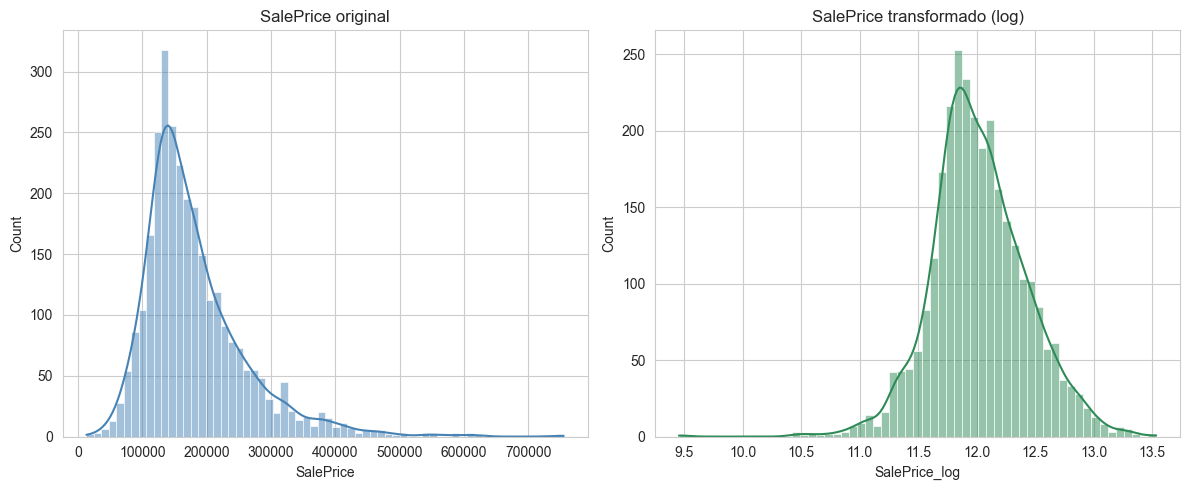

In [19]:
df_prep["SalePrice_log"] = np.log1p(df_prep["SalePrice"])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(df_prep["SalePrice"], kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("SalePrice original")
sns.histplot(df_prep["SalePrice_log"], kde=True, ax=axes[1], color="seagreen")
axes[1].set_title("SalePrice transformado (log)")
plt.tight_layout()
plt.savefig("../images/transformacion_log_saleprice.png", dpi=120)
plt.show()


La transformación logarítmica reduce notoriamente la asimetría de la variable objetivo, acercándola a una distribución normal, lo que favorecerá el desempeño de modelos como la Regresión Lineal en etapas posteriores.

### 9.5 Codificación de variables categóricas

Se separan las variables predictoras (`X`) del objetivo (`y`), y se identifican las columnas numéricas y categóricas para aplicar la codificación adecuada.


In [20]:
# Separación de variables predictoras y variable objetivo
X = df_prep.drop(columns=["SalePrice", "SalePrice_log"])
y = df_prep["SalePrice_log"]  # se usa la versión log-transformada como objetivo de modelamiento

# Identificación de columnas numéricas y categóricas
num_features = X.select_dtypes(include=[np.number]).columns.tolist()
cat_features = X.select_dtypes(include=["object"]).columns.tolist()

print(f"Variables numéricas: {len(num_features)}")
print(f"Variables categóricas: {len(cat_features)}")


Variables numéricas: 36
Variables categóricas: 43


### 9.6 Pipeline de preprocesamiento (imputación + escalado + codificación)

Se construye un `Pipeline` de `scikit-learn` que:
1. Imputa valores numéricos faltantes con la mediana (medida de seguridad adicional).
2. Escala las variables numéricas con `StandardScaler`.
3. Codifica variables categóricas con `OneHotEncoder`.

Este pipeline permite aplicar exactamente las mismas transformaciones al set de entrenamiento y de prueba, evitando fuga de información (*data leakage*).


In [21]:
# Pipeline para variables numéricas
num_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Pipeline para variables categóricas
cat_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combinación de ambos pipelines en un ColumnTransformer
preprocessor = ColumnTransformer(transformers=[
    ("num", num_pipeline, num_features),
    ("cat", cat_pipeline, cat_features)
])

preprocessor


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. `

### 9.7 División en conjuntos de entrenamiento y prueba

Se reserva un **80%** de los datos para entrenamiento y un **20%** para prueba. Esta división es la que se usará en la etapa de modelamiento para evaluar los 3 algoritmos candidatos (sección 4) según las métricas y umbrales definidos (secciones 5 y 6).


In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Set de entrenamiento: {X_train.shape[0]} filas")
print(f"Set de prueba: {X_test.shape[0]} filas")


Set de entrenamiento: 2341 filas
Set de prueba: 586 filas


In [23]:
# Ajuste del preprocesador SOLO con datos de entrenamiento (para evitar data leakage)
X_train_transformed = preprocessor.fit_transform(X_train)
X_test_transformed = preprocessor.transform(X_test)

print(f"Dimensiones de X_train luego del preprocesamiento: {X_train_transformed.shape}")
print(f"Dimensiones de X_test luego del preprocesamiento: {X_test_transformed.shape}")


Dimensiones de X_train luego del preprocesamiento: (2341, 314)
Dimensiones de X_test luego del preprocesamiento: (586, 314)


### 9.8 Guardado de los datos preparados

Se exportan los conjuntos de datos limpios y transformados a la carpeta `data/`, dejando el proyecto listo para la siguiente etapa de modelamiento.


In [24]:
import joblib

# Dataset limpio (sin transformaciones de encoding, útil para futuras exploraciones)
df_prep.to_csv("../data/housing_clean.csv", index=False)

# División de datos lista para modelamiento
X_train.to_csv("../data/X_train.csv", index=False)
X_test.to_csv("../data/X_test.csv", index=False)
y_train.to_csv("../data/y_train.csv", index=False)
y_test.to_csv("../data/y_test.csv", index=False)

# Se guarda el pipeline de preprocesamiento entrenado para reutilizarlo en el modelamiento
joblib.dump(preprocessor, "../models/preprocessor_pipeline.pkl")

print("Archivos de datos preparados y pipeline de preprocesamiento guardados exitosamente.")


Archivos de datos preparados y pipeline de preprocesamiento guardados exitosamente.


<a id="10"></a>
## 10. Análisis de Sesgos

- **Sesgo geográfico/temporal:** el dataset corresponde únicamente a la ciudad de **Ames, Iowa**, entre **2006 y 2010** (periodo que incluye la crisis subprime en EE.UU.). Un modelo entrenado con estos datos **no debería generalizarse** a otras ciudades, países, ni a condiciones de mercado muy distintas (por ejemplo, el mercado inmobiliario chileno) sin una validación adicional.
- **Sesgo socioeconómico vía `Neighborhood`:** como se observó en la sección 8.5, el barrio es una variable con alto poder predictivo. Esto implica un riesgo de que el modelo **replique y refuerce desigualdades históricas** entre barrios (por ejemplo, barrios históricamente menos valorados seguirán prediciéndose con precios bajos, incluso si las condiciones cambian). Es importante que el modelo se use como **apoyo a la decisión** y no como única fuente de verdad, especialmente en contextos donde podría influir en decisiones de crédito hipotecario o políticas urbanas.
- **Sesgo de selección:** el dataset solo incluye **viviendas efectivamente vendidas**, por lo que no representa a la totalidad del parque habitacional (quedan fuera viviendas que no se transaron en el periodo, lo cual podría subrepresentar ciertos segmentos del mercado).
- **Variables sensibles indirectas (proxy bias):** si bien no hay variables explícitas de raza, género o nivel socioeconómico de las personas, variables como `Neighborhood` pueden actuar como **proxy** de composición socioeconómica o étnica de un sector, un fenómeno documentado en la literatura de *fairness in ML* para modelos de tasación inmobiliaria. Se recomienda, en etapas futuras de modelamiento, evaluar el desempeño del modelo de forma **desagregada por barrio** para detectar posibles inequidades sistemáticas en el error de predicción (por ejemplo, verificar si el MAE/MAPE es sistemáticamente peor en ciertos barrios).
- **Mitigación propuesta:** documentar explícitamente el alcance geográfico/temporal del modelo, monitorear métricas de error por subgrupo (`Neighborhood`) y evitar el uso del modelo como única fuente de decisión en contextos con impacto directo sobre personas (créditos, seguros).


<a id="11"></a>
## 11. Consideraciones de Ética y Privacidad

### 11.1 Privacidad de los datos

- El dataset **no contiene información personal identificable (PII)**: no incluye nombres de propietarios, direcciones exactas, RUT/SSN, ni datos de contacto. El identificador de cada registro (`PID`) corresponde a un número de parcela catastral (*Parcel ID*), de carácter público en Ames, Iowa, y no permite identificar directamente a una persona natural.
- Aun así, se recomienda **no cruzar este dataset con otras fuentes** (por ejemplo, registros públicos de propietarios) que sí podrían re-identificar a personas, ya que la combinación de variables muy específicas (ubicación exacta + características únicas de la vivienda) podría en teoría acotar la identificación de un inmueble específico y, por extensión, de su propietario.

### 11.2 Consideraciones éticas de uso

- El modelo resultante debe entenderse como una **herramienta de apoyo a la tasación**, no como un reemplazo del criterio profesional de un tasador certificado, especialmente en decisiones con impacto financiero relevante (créditos hipotecarios, seguros, etc.).
- Se recomienda **transparentar las variables** que más influyen en cada predicción (por ejemplo, mediante técnicas de interpretabilidad como SHAP en etapas futuras), de modo que un cliente pueda entender por qué se le entrega determinado precio de referencia.
- Cualquier despliegue productivo del modelo debería incluir un **monitoreo periódico** para detectar *data drift* (cambios en el mercado inmobiliario que vuelvan obsoletas las predicciones) y sesgos emergentes, en línea con lo identificado en la sección 10.
- El uso del modelo debe ser **consistente con la normativa local de protección de datos** vigente en el territorio donde se despliegue (por ejemplo, en Chile, la Ley N°19.628 sobre Protección de la Vida Privada), especialmente si en el futuro se integran datos adicionales que sí contengan información personal de compradores o vendedores.


## Conclusiones y próximos pasos

### Conclusiones de esta etapa

1. El dataset Ames Housing es una fuente de datos **robusta y de buena calidad** para el problema de negocio planteado, con muy pocos duplicados y valores faltantes reales (la mayoría de los "nulos" son en realidad ausencia de un atributo, no errores).
2. Las variables con mayor relación con el precio de venta son la **calidad general de la construcción** (`Overall Qual`), la **superficie habitable** (`Gr Liv Area`), la **capacidad del garage** y el **barrio** (`Neighborhood`), consistente con el sentido común inmobiliario.
3. Se aplicó una **transformación logarítmica** a la variable objetivo para corregir su asimetría, y se construyó un **pipeline reproducible** de imputación, escalado y codificación, dejando los datos listos para el modelamiento.
4. Se identificaron y trataron **outliers evidentes** (viviendas muy grandes con precios anormalmente bajos) que podrían haber distorsionado modelos futuros.
5. Se preseleccionaron **3 algoritmos candidatos** (Regresión Lineal, Random Forest, Gradient Boosting) y se definieron **métricas y umbrales concretos** (R² ≥ 0.80, RMSE ≤ US$ 30.000, MAE ≤ US$ 20.000, MAPE ≤ 12%) para evaluar objetivamente el éxito del modelo en la siguiente etapa.
6. Se documentaron los **riesgos de sesgo y las consideraciones éticas/de privacidad** más relevantes, principalmente asociados al uso de la variable `Neighborhood` como proxy socioeconómico y a la representatividad geográfica/temporal limitada del dataset.

### Próximos pasos (fuera del alcance de esta evaluación)

- Entrenar los 3 algoritmos candidatos sobre `X_train_transformed` / `y_train`.
- Evaluar cada modelo con las métricas definidas (RMSE, MAE, R², MAPE) sobre el set de prueba y contrastarlas contra los umbrales de la sección 6.
- Realizar ajuste de hiperparámetros (*hyperparameter tuning*) y validación cruzada.
- Analizar la interpretabilidad del modelo final (importancia de variables, SHAP) y su desempeño desagregado por barrio para verificar los riesgos de sesgo identificados en la sección 10.


<br>

---
---
# ══════════════════════════════════════════
# PARTE 2 — EVALUACIÓN PARCIAL N°2
### Presentación y defensa técnica del proyecto de Machine Learning
# ══════════════════════════════════════════
**Asignatura:** MLY1101 Machine Learning · **Ponderación:** 40% · **Modalidad:** trabajo grupal (1 semana) con **defensa individual** y preguntas cruzadas · **Presentación:** 15 minutos por equipo

**Caso elegido:** Caso B — Predicción de precios de viviendas (*Housing Prices*), el mismo de la Evaluación 1.

**Regla de esta parte:** todo lo que se hace aquí **parte de las decisiones ya tomadas en la Evaluación 1** (metodología, algoritmos, métricas, umbrales, preparación de datos y división train/test). No se reabre ninguna de ellas; se ejecutan, se miden y se interpretan.

## Índice de la Parte 2
12. [Mapa de cumplimiento de la Evaluación 2](#12)
13. [Aplicación de la metodología CRISP-DM](#13)
14. [Decisiones heredadas de la Evaluación 1](#14)
15. [Justificación de la selección de modelos](#15)
16. [Detalle de las variables finales por modelo](#16)
17. [Implementación de los modelos supervisados](#17)
18. [Evaluación y selección del modelo](#18)
19. [Implementación del modelo no supervisado (segmentación)](#19)
20. [Interpretación del desempeño y recomendaciones de negocio](#20)
21. [Conclusiones finales y limitaciones](#21)
22. [Entregables y guía para la presentación](#22)

---
---


<a id="12"></a>
## 12. Mapa de cumplimiento de la Evaluación 2

### 12.1 Indicadores de la rúbrica y dónde se cubre cada uno

| Indicador | Pond. | Qué exige para el 100% | Dónde se cubre |
|---|---|---|---|
| **IE5** — Aplicación de la metodología | 20% | Metodología de ciencia de datos aplicada con todas las etapas estructuradas de forma coherente | Sección 13 (CRISP-DM) + Parte 1 completa |
| **IE6** — Modelos de aprendizaje supervisado | 30% | Modelos adecuados al problema, con selección del algoritmo y su configuración justificadas | Secciones 15, 16 y 17 |
| **IE7** — Modelos de aprendizaje no supervisado | 30% | Modelos no supervisados que identifiquen patrones relevantes y justifiquen su aplicación al negocio | Sección 19 |
| **IE8** — Interpretación del desempeño | 20% | Métricas interpretadas correctamente y traducidas a recomendaciones para el negocio | Secciones 18 y 20 |

### 12.2 Apartados que debe incluir la presentación

| Apartado exigido | Dónde está |
|---|---|
| Descripción del problema de negocio y objetivos | Parte 1 · secciones 1 y 2 |
| EDA: patrones, calidad de datos y variables relevantes | Parte 1 · sección 8 |
| Preparación y transformación de datos | Parte 1 · sección 9 |
| Implementación de 3 modelos de ML | Parte 2 · secciones 17 y 19 |
| Evaluación con métricas apropiadas | Parte 2 · sección 18 |

### 12.3 Secciones mínimas del informe técnico (README.md) y su fuente en este notebook

| Sección exigida del informe | Fuente en este notebook |
|---|---|
| Descripción del problema de negocio | Sección 1 |
| Objetivos del proyecto | Sección 2 |
| Descripción de las fuentes de datos | Sección 7 |
| Análisis exploratorio (EDA) | Sección 8 |
| Preparación y transformación de los datos | Sección 9 |
| Justificación de la selección de modelos (mínimo 3) | Sección 15 (y sección 4 de la Parte 1) |
| Detalles y características de las variables finales por modelo | Sección 16 |
| Implementación de los modelos seleccionados | Secciones 17 y 19 |
| Evaluación y selección del modelo según las métricas | Sección 18 |


<a id="13"></a>
## 13. Aplicación de la metodología CRISP-DM (IE5)

La metodología declarada desde la Evaluación 1 es **CRISP-DM**. El proyecto completo recorre sus seis fases así:

| Fase CRISP-DM | Qué se hizo en este proyecto | Dónde |
|---|---|---|
| 1. Comprensión del negocio | Problema de tasación inconsistente y lenta; objetivos; tipo de problema (regresión); métricas y **criterio de salida cuantitativo** | Parte 1 · secciones 1 a 6 |
| 2. Comprensión de los datos | Descripción de la fuente, calidad (duplicados, nulos, outliers), patrones y variables relevantes | Parte 1 · secciones 7 y 8 |
| 3. Preparación de los datos | Limpieza, imputación diferenciada, transformación log del objetivo, pipeline de imputación + escalado + One-Hot, división 80/20 | Parte 1 · sección 9 |
| 4. Modelado | 3 modelos supervisados con ajuste de hiperparámetros por validación cruzada + segmentación no supervisada | Parte 2 · secciones 15 a 17 y 19 |
| 5. Evaluación | Métricas en el conjunto de prueba, contraste con los umbrales, análisis por barrio, por tramo de precio y por segmento | Parte 2 · secciones 18 y 20 |
| 6. Despliegue | Modelo final guardado como pipeline completo (`.pkl`), prueba de recarga y recomendaciones de uso y monitoreo. **No se despliega en producción**; queda preparado para hacerlo | Parte 2 · secciones 18.8 y 20 |

**Naturaleza iterativa de CRISP-DM — un ejemplo real de este proyecto:** al explorar la segmentación (fase 4) se observó que una de las variables de mayor correlación con el precio, `Garage Yr Blt`, contiene el valor `0` para las viviendas sin garage (decisión de imputación de la sección 9.2). Ese `0` no es un año real y generaba un segmento artificial de «casas sin garage». Se volvió a la fase 3 para razonar el problema y se excluyó esa variable **solo de la segmentación**, sin tocar el resto de la preparación.


<a id="14"></a>
## 14. Decisiones heredadas de la Evaluación 1

Estas son las decisiones ya tomadas que la Parte 2 **ejecuta tal cual**:

| Decisión de la Evaluación 1 | Sección | Cómo se usa en la Evaluación 2 |
|---|---|---|
| Problema de **regresión supervisada** sobre `SalePrice` | 3 | Los 3 modelos supervisados son regresores |
| **3 algoritmos candidatos:** Regresión Lineal con Ridge/Lasso, Random Forest, Gradient Boosting | 4 | Son exactamente los 3 modelos entrenados en la sección 17 |
| **Métricas:** RMSE, MAE, R², MAPE | 5 | Se calculan las 4 sobre el conjunto de prueba, en dólares |
| **Umbrales de aceptación:** R² ≥ 0.80 · RMSE ≤ US$ 30.000 · MAE ≤ US$ 20.000 · MAPE ≤ 12% | 6 | Criterio de salida para validar los modelos (sección 18.2) |
| Se eliminan `Order` y `PID` y **3 outliers** (> 4.000 pies² y < US$ 300.000) | 8.6 y 9.1 | El modelamiento usa las 2.927 viviendas restantes |
| Nulos «estructurales» → `"None"` / `0`; nulos reales → mediana por barrio (`Lot Frontage`) o moda (`Electrical`) | 9.2 y 9.3 | Los 3 nulos que aún quedan (viviendas de barrios sin ningún `Lot Frontage` registrado) los resuelve el imputador del pipeline |
| Objetivo transformado con **`log1p(SalePrice)`** | 9.4 | Los modelos se entrenan sobre el logaritmo; las métricas se calculan **volviendo a dólares** con `expm1` |
| **Pipeline** de imputación + `StandardScaler` + `OneHotEncoder` ajustado solo con train | 9.6 | Se reutiliza (clonado) dentro de cada modelo, de modo que la validación cruzada tampoco filtra información |
| División **80/20** con `random_state=42` | 9.7 | Mismos conjuntos `X_train` (2.341) y `X_test` (586) |
| Riesgo de sesgo por `Neighborhood` y compromiso de medir el error **por barrio** | 10 | Se cumple en la sección 18.6 |
| Uso del modelo como **apoyo a la tasación**, con monitoreo de *drift* | 11 | Guía las recomendaciones de la sección 20 |


<a id="15"></a>
## 15. Justificación de la selección de modelos (IE6 e IE7)

### 15.1 Modelos supervisados (los 3 definidos en la Evaluación 1)

| N° | Modelo | Por qué corresponde al problema | Configuración que se explora |
|---|---|---|---|
| 1 | **Regresión Lineal regularizada** (Ridge y Lasso; se conserva el mejor) | Línea base **interpretable**. Tras el `log1p` del objetivo la relación con las variables es más lineal. La regularización es necesaria porque el One-Hot deja **314 columnas** para 2.341 filas y varias variables están muy correlacionadas (p. ej. `Gr Liv Area`, `1st Flr SF`, `2nd Flr SF`): sin regularizar, los coeficientes serían inestables | `alpha` de Ridge: 0,1 a 100 · `alpha` de Lasso: 0,0001 a 0,01 |
| 2 | **Random Forest Regressor** | Captura **no linealidades e interacciones** (p. ej. calidad × barrio) sin especificarlas, es robusto a outliers y entrega importancia de variables | `max_depth`, `min_samples_leaf`, `max_features` (200 árboles; búsqueda aleatoria de 5 combinaciones) |
| 3 | **Gradient Boosting Regressor** | Suele dar el **mejor desempeño predictivo** en datos tabulares de este tamaño; es el «techo de desempeño» de la comparación | `n_estimators` (300 y 500), `learning_rate=0,05`, `max_depth` (3 y 4), `subsample=0,8`, `max_features=0,5` |

**Cómo se ajusta cada uno (igual para los tres, para que la comparación sea justa):**
- Se entrena un `Pipeline` = preprocesador de la Evaluación 1 + modelo, de modo que imputación, escalado y One-Hot se reajustan **dentro de cada partición** de la validación cruzada (sin fuga de información).
- Los hiperparámetros se eligen con **validación cruzada de 3 particiones sobre el conjunto de entrenamiento**, minimizando el RMSE sobre el logaritmo del precio.
- El conjunto de prueba **no participa** en la elección de hiperparámetros; solo se usa para la evaluación final.
- Se usan pocas combinaciones y 3 particiones por una razón práctica: mantener la ejecución del notebook en minutos. Es una limitación declarada en la sección 21.

### 15.2 Modelo no supervisado (complemento)

| Modelo | Por qué se agrega | Qué aporta al negocio |
|---|---|---|
| **K-Means** (con apoyo de PCA para visualizar) | La rúbrica evalúa explícitamente el aprendizaje **no supervisado** (IE7, 30%) y el enunciado pide modelos supervisados **o** no supervisados según el caso. Los 3 modelos supervisados de la Evaluación 1 cumplen el mínimo de 3; K-Means se **suma** como cuarto modelo sin reemplazar a ninguno | Segmentar el mercado en **tipos de vivienda** a partir de sus características físicas (sin usar el precio), validar que esos segmentos tengan precios distintos y revisar si el modelo supervisado rinde igual en todos ellos |

K-Means es adecuado porque las variables de segmentación son numéricas y continuas (se estandarizan), se busca una partición simple y explicable, y el tamaño del dataset es pequeño.

A continuación se cargan las librerías adicionales y se verifica que la Parte 1 se ejecutó.


#### Configuración inicial de la Parte 2

In [25]:
# Librerías adicionales para la etapa de modelamiento (Evaluación 2)
import time
from sklearn.base import clone
from sklearn.linear_model import Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, KFold
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             mean_absolute_percentage_error, silhouette_score)
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

RANDOM_STATE = 42   # misma semilla usada en la división train/test de la Evaluación 1

# Verificación: este bloque depende de las variables creadas en la Parte 1 (ejecutar el notebook de arriba hacia abajo)
for var in ["df_prep", "X_train", "X_test", "y_train", "y_test", "preprocessor", "num_features", "cat_features"]:
    assert var in globals(), f"Falta la variable '{var}': ejecute primero la Parte 1 (Evaluación 1)."

print(f"Train: {X_train.shape} | Test: {X_test.shape}")
print(f"Variables numéricas: {len(num_features)} | categóricas: {len(cat_features)}")

Train: (2341, 79) | Test: (586, 79)
Variables numéricas: 36 | categóricas: 43


<a id="16"></a>
## 16. Detalle de las variables finales por modelo

Todos los modelos supervisados reciben **las mismas variables**, producidas por el pipeline de la sección 9.6. Esto es una decisión deliberada: así las diferencias de desempeño se deben al algoritmo y no a una selección distinta de variables.

| Modelo | Variables de entrada | Tratamiento aplicado | Observación |
|---|---|---|---|
| **Regresión Lineal (Ridge / Lasso)** | **314 columnas:** 36 numéricas + 278 *dummies* de 43 variables categóricas | Imputación por mediana / moda, `StandardScaler` en numéricas, `OneHotEncoder` en categóricas | El escalado es indispensable para que la penalización afecte por igual a todas las variables. Lasso termina conservando solo una parte de las columnas (ver sección 17.1) |
| **Random Forest** | Las mismas 314 columnas | Mismo pipeline | Los árboles no necesitan escalado, pero se mantiene el mismo pipeline por comparabilidad. El One-Hot reparte la importancia de una variable categórica entre sus *dummies* |
| **Gradient Boosting** | Las mismas 314 columnas | Mismo pipeline | Ídem |
| **K-Means** (no supervisado) | **9 variables numéricas** de mayor correlación con el precio: `Overall Qual`, `Gr Liv Area`, `Garage Cars`, `Garage Area`, `Total Bsmt SF`, `1st Flr SF`, `Year Built`, `Full Bath`, `Year Remod/Add` | `StandardScaler` | **No** incluye `SalePrice` (para poder validar los segmentos con el precio) ni `Garage Yr Blt` (valor `0` artificial, ver sección 13) |

**Variable objetivo de los modelos supervisados:** `SalePrice_log = log1p(SalePrice)`. **Excluidas del modelamiento:** `Order`, `PID` (identificadores) y el propio `SalePrice` original.

La siguiente celda verifica estas cifras directamente sobre los datos.


In [26]:
# Número de variables que realmente recibe cada modelo tras el preprocesamiento de la Evaluación 1
prep_demo = clone(preprocessor).fit(X_train)
nombres_features = prep_demo.get_feature_names_out()
n_num = len(num_features)
n_total = len(nombres_features)

print(f"Variables originales (sin Order/PID/SalePrice): {X_train.shape[1]}  ->  {n_num} numéricas + {len(cat_features)} categóricas")
print(f"Columnas tras imputación + escalado + One-Hot Encoding: {n_total}  ->  {n_num} numéricas escaladas + {n_total - n_num} dummies")
print("\nEjemplo de columnas generadas por One-Hot (barrio):")
print([n for n in nombres_features if "Neighborhood" in n][:6], "...")

Variables originales (sin Order/PID/SalePrice): 79  ->  36 numéricas + 43 categóricas
Columnas tras imputación + escalado + One-Hot Encoding: 314  ->  36 numéricas escaladas + 278 dummies

Ejemplo de columnas generadas por One-Hot (barrio):
['cat__Neighborhood_Blmngtn', 'cat__Neighborhood_Blueste', 'cat__Neighborhood_BrDale', 'cat__Neighborhood_BrkSide', 'cat__Neighborhood_ClearCr', 'cat__Neighborhood_CollgCr'] ...


<a id="17"></a>
## 17. Implementación de los modelos supervisados (IE6)

Primero se definen tres funciones auxiliares: una que arma el pipeline completo, una que calcula las 4 métricas **en dólares** (devolviendo las predicciones del logaritmo a su escala original con `expm1`) y una que entrena y registra cada modelo.

> **Nota:** la validación cruzada optimiza el RMSE en escala logarítmica (la escala en la que se entrena); las métricas finales de la sección 18 en adelante están en dólares, que es la escala de los umbrales de la Evaluación 1.


In [27]:
# Funciones auxiliares: pipeline completo (preprocesamiento + modelo) y evaluación en dólares
# El modelo se entrena sobre log1p(SalePrice) (decisión de la Evaluación 1) y las métricas se calculan
# volviendo a dólares con expm1, que es la escala en la que se definieron los umbrales (sección 6).
cv_kf = KFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

def armar_pipeline(estimador):
    """Pipeline: preprocesador de la Evaluación 1 (clonado, sin ajustar) + estimador."""
    return Pipeline(steps=[("prep", clone(preprocessor)), ("model", estimador)])

def metricas(y_log_real, y_log_pred):
    y_real, y_pred = np.expm1(y_log_real), np.expm1(y_log_pred)
    return {
        "R2":   r2_score(y_real, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_real, y_pred)),
        "MAE":  mean_absolute_error(y_real, y_pred),
        "MAPE": mean_absolute_percentage_error(y_real, y_pred) * 100,
    }

resultados = {}      # métricas test por modelo
mejores = {}         # mejor pipeline por modelo
cv_info = {}         # información de validación cruzada

def entrenar(nombre, estimador, grilla, tipo="grid", n_iter=8):
    inicio = time.time()
    pipe = armar_pipeline(estimador)
    if tipo == "grid":
        busq = GridSearchCV(pipe, grilla, cv=cv_kf, scoring="neg_root_mean_squared_error", n_jobs=-1)
    else:
        busq = RandomizedSearchCV(pipe, grilla, n_iter=n_iter, cv=cv_kf, scoring="neg_root_mean_squared_error",
                                  random_state=RANDOM_STATE, n_jobs=-1)
    busq.fit(X_train, y_train)
    mejores[nombre] = busq.best_estimator_
    cv_info[nombre] = {"mejores_params": busq.best_params_, "cv_rmse_log": -busq.best_score_}
    m_test = metricas(y_test, busq.best_estimator_.predict(X_test))
    m_train = metricas(y_train, busq.best_estimator_.predict(X_train))
    resultados[nombre] = {**m_test, "R2_train": m_train["R2"], "tiempo_s": time.time() - inicio}
    print(f"[{nombre}] mejores hiperparámetros: {busq.best_params_}")
    print(f"    RMSE CV (escala log): {-busq.best_score_:.4f} | R2 test: {m_test['R2']:.4f} | "
          f"RMSE test: US$ {m_test['RMSE']:,.0f} | tiempo: {time.time()-inicio:.0f}s")

### 17.1 Modelo 1 — Regresión Lineal regularizada (Ridge y Lasso)

Se ajustan ambas variantes y se conserva la mejor según la validación cruzada. **Ridge** reduce los coeficientes sin anularlos (bueno cuando muchas variables aportan un poco); **Lasso** lleva a cero los coeficientes de las variables menos útiles (selección automática de variables).


In [28]:
# Modelo 1a: Regresión Ridge (regresión lineal múltiple con regularización L2)
entrenar("Ridge", Ridge(random_state=RANDOM_STATE),
         {"model__alpha": [0.1, 0.3, 1, 3, 10, 30, 100]})

# Modelo 1b: Regresión Lasso (regularización L1, realiza selección automática de variables)
entrenar("Lasso", Lasso(max_iter=50000, random_state=RANDOM_STATE),
         {"model__alpha": [0.0001, 0.0003, 0.001, 0.003, 0.01]})

[Ridge] mejores hiperparámetros: {'model__alpha': 30}
    RMSE CV (escala log): 0.1229 | R2 test: 0.9590 | RMSE test: US$ 18,169 | tiempo: 10s
[Lasso] mejores hiperparámetros: {'model__alpha': 0.001}
    RMSE CV (escala log): 0.1237 | R2 test: 0.9560 | RMSE test: US$ 18,829 | tiempo: 1s


**Lectura de resultados:** el RMSE de validación cruzada de Ridge y Lasso es prácticamente el mismo, y se conserva **Ridge** por tener el menor valor. Lasso demuestra además que gran parte de las 314 columnas es prescindible: lo esencial del precio lo explica un subconjunto reducido de variables.


In [29]:
# Entre Ridge y Lasso se conserva como "Regresión Lineal regularizada" el de menor RMSE en validación cruzada
mejor_lineal = min(["Ridge", "Lasso"], key=lambda n: cv_info[n]["cv_rmse_log"])
print(f"Modelo lineal seleccionado: {mejor_lineal}")
print(pd.DataFrame({n: {"alpha": cv_info[n]["mejores_params"]["model__alpha"],
                        "RMSE CV (log)": round(cv_info[n]["cv_rmse_log"], 4)} for n in ["Ridge", "Lasso"]}).T)

# Cuántas variables conserva Lasso (coeficientes distintos de cero)
coef_lasso = mejores["Lasso"].named_steps["model"].coef_
print(f"\nLasso conserva {np.sum(coef_lasso != 0)} de {len(coef_lasso)} columnas ({np.mean(coef_lasso == 0)*100:.0f}% con coeficiente 0).")

Modelo lineal seleccionado: Ridge
        alpha  RMSE CV (log)
Ridge  30.000         0.1229
Lasso   0.001         0.1237

Lasso conserva 81 de 314 columnas (74% con coeficiente 0).


### 17.2 Modelo 2 — Random Forest Regressor


In [30]:
# Modelo 2: Random Forest Regressor
entrenar("Random Forest",
         RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
         {"model__max_depth": [None, 15, 25],
          "model__min_samples_leaf": [1, 2, 4],
          "model__max_features": [0.2, 0.33, 0.5]},
         tipo="random", n_iter=5)

[Random Forest] mejores hiperparámetros: {'model__min_samples_leaf': 2, 'model__max_features': 0.33, 'model__max_depth': 15}
    RMSE CV (escala log): 0.1376 | R2 test: 0.9206 | RMSE test: US$ 25,293 | tiempo: 19s


### 17.3 Modelo 3 — Gradient Boosting Regressor


In [31]:
# Modelo 3: Gradient Boosting Regressor
entrenar("Gradient Boosting",
         GradientBoostingRegressor(random_state=RANDOM_STATE),
         {"model__n_estimators": [300, 500],
          "model__learning_rate": [0.05],
          "model__max_depth": [3, 4],
          "model__subsample": [0.8],
          "model__max_features": [0.5]})

[Gradient Boosting] mejores hiperparámetros: {'model__learning_rate': 0.05, 'model__max_depth': 4, 'model__max_features': 0.5, 'model__n_estimators': 500, 'model__subsample': 0.8}
    RMSE CV (escala log): 0.1245 | R2 test: 0.9533 | RMSE test: US$ 19,403 | tiempo: 12s


<a id="18"></a>
## 18. Evaluación y selección del modelo (IE8)

### 18.1 Comparación en el conjunto de prueba

Las métricas se calculan sobre las **586 viviendas de prueba**, que ningún modelo vio durante el entrenamiento ni durante la elección de hiperparámetros. `R2_train` se incluye para vigilar el sobreajuste.


In [32]:
# Tabla comparativa de los modelos sobre el conjunto de prueba (valores en US$)
modelos_finales = [mejor_lineal, "Random Forest", "Gradient Boosting"]
etiquetas = {mejor_lineal: f"Regresión Lineal ({mejor_lineal})",
             "Random Forest": "Random Forest", "Gradient Boosting": "Gradient Boosting"}

tabla = pd.DataFrame({etiquetas[n]: resultados[n] for n in modelos_finales}).T
tabla = tabla[["R2", "RMSE", "MAE", "MAPE", "R2_train"]]
tabla["RMSE CV (log)"] = [cv_info[n]["cv_rmse_log"] for n in modelos_finales]
tabla.round({"R2": 4, "RMSE": 0, "MAE": 0, "MAPE": 2, "R2_train": 4, "RMSE CV (log)": 4})

,R2,RMSE,MAE,MAPE,R2_train,RMSE CV (log)
Regresión Lineal (Ridge),0.9590,18169.0,12574.0,7.15,0.9444,0.1229
Random Forest,0.9206,25293.0,14725.0,7.88,0.9758,0.1376
Gradient Boosting,0.9533,19403.0,12508.0,6.87,0.9873,0.1245


### 18.2 Contraste con los umbrales de aceptación (criterio de salida de la sección 6)


In [33]:
# Contraste contra los umbrales de aceptación definidos en la sección 6 (Evaluación 1)
umbrales = {"R2": (">=", 0.80), "RMSE": ("<=", 30000), "MAE": ("<=", 20000), "MAPE": ("<=", 12)}

def cumple(valor, op, umbral):
    return valor >= umbral if op == ">=" else valor <= umbral

verif = pd.DataFrame({
    etiquetas[n]: {m: ("CUMPLE" if cumple(resultados[n][m], *umbrales[m]) else "NO CUMPLE") for m in umbrales}
    for n in modelos_finales
}).T
verif["¿Cumple los 4?"] = (verif == "CUMPLE").all(axis=1).map({True: "SI", False: "NO"})
print("Umbrales:", {k: f"{v[0]} {v[1]:,}" for k, v in umbrales.items()})
verif

Umbrales: {'R2': '>= 0.8', 'RMSE': '<= 30,000', 'MAE': '<= 20,000', 'MAPE': '<= 12'}


,R2,RMSE,MAE,MAPE,¿Cumple los 4?
Regresión Lineal (Ridge),CUMPLE,CUMPLE,CUMPLE,CUMPLE,SI
Random Forest,CUMPLE,CUMPLE,CUMPLE,CUMPLE,SI
Gradient Boosting,CUMPLE,CUMPLE,CUMPLE,CUMPLE,SI


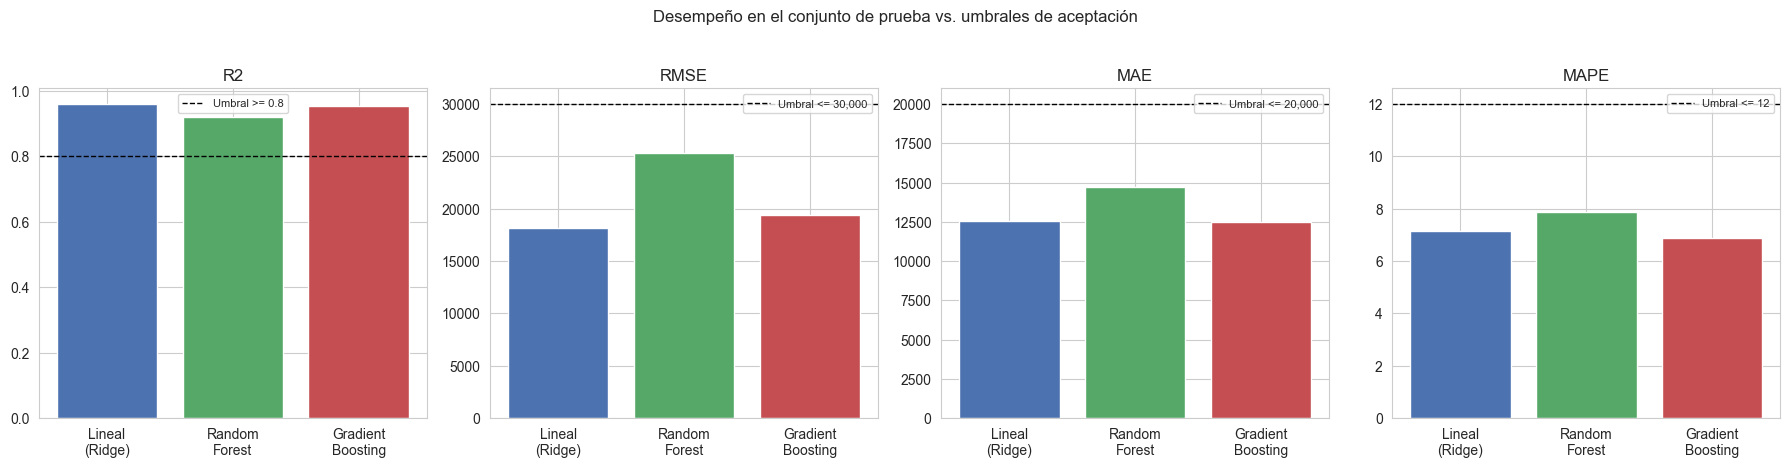

In [34]:
# Comparación visual de las métricas por modelo (con la línea del umbral de la sección 6)
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
colores = ["#4c72b0", "#55a868", "#c44e52"]
for ax, m in zip(axes, ["R2", "RMSE", "MAE", "MAPE"]):
    vals = [resultados[n][m] for n in modelos_finales]
    ax.bar([etiquetas[n].replace("Regresión Lineal ", "Lineal\n") .replace(" ", "\n", 1) for n in modelos_finales], vals, color=colores)
    ax.axhline(umbrales[m][1], color="black", linestyle="--", linewidth=1, label=f"Umbral {umbrales[m][0]} {umbrales[m][1]:,}")
    ax.set_title(m)
    ax.legend(fontsize=8)
plt.suptitle("Desempeño en el conjunto de prueba vs. umbrales de aceptación", y=1.03)
plt.tight_layout()
plt.savefig("../images/comparacion_metricas.png", dpi=120, bbox_inches="tight")
plt.show()

### 18.3 Precio real vs. predicho y residuos

Si el modelo fuera perfecto, los puntos de la fila superior caerían sobre la diagonal y los residuos de la fila inferior se repartirían alrededor de 0 sin patrón.


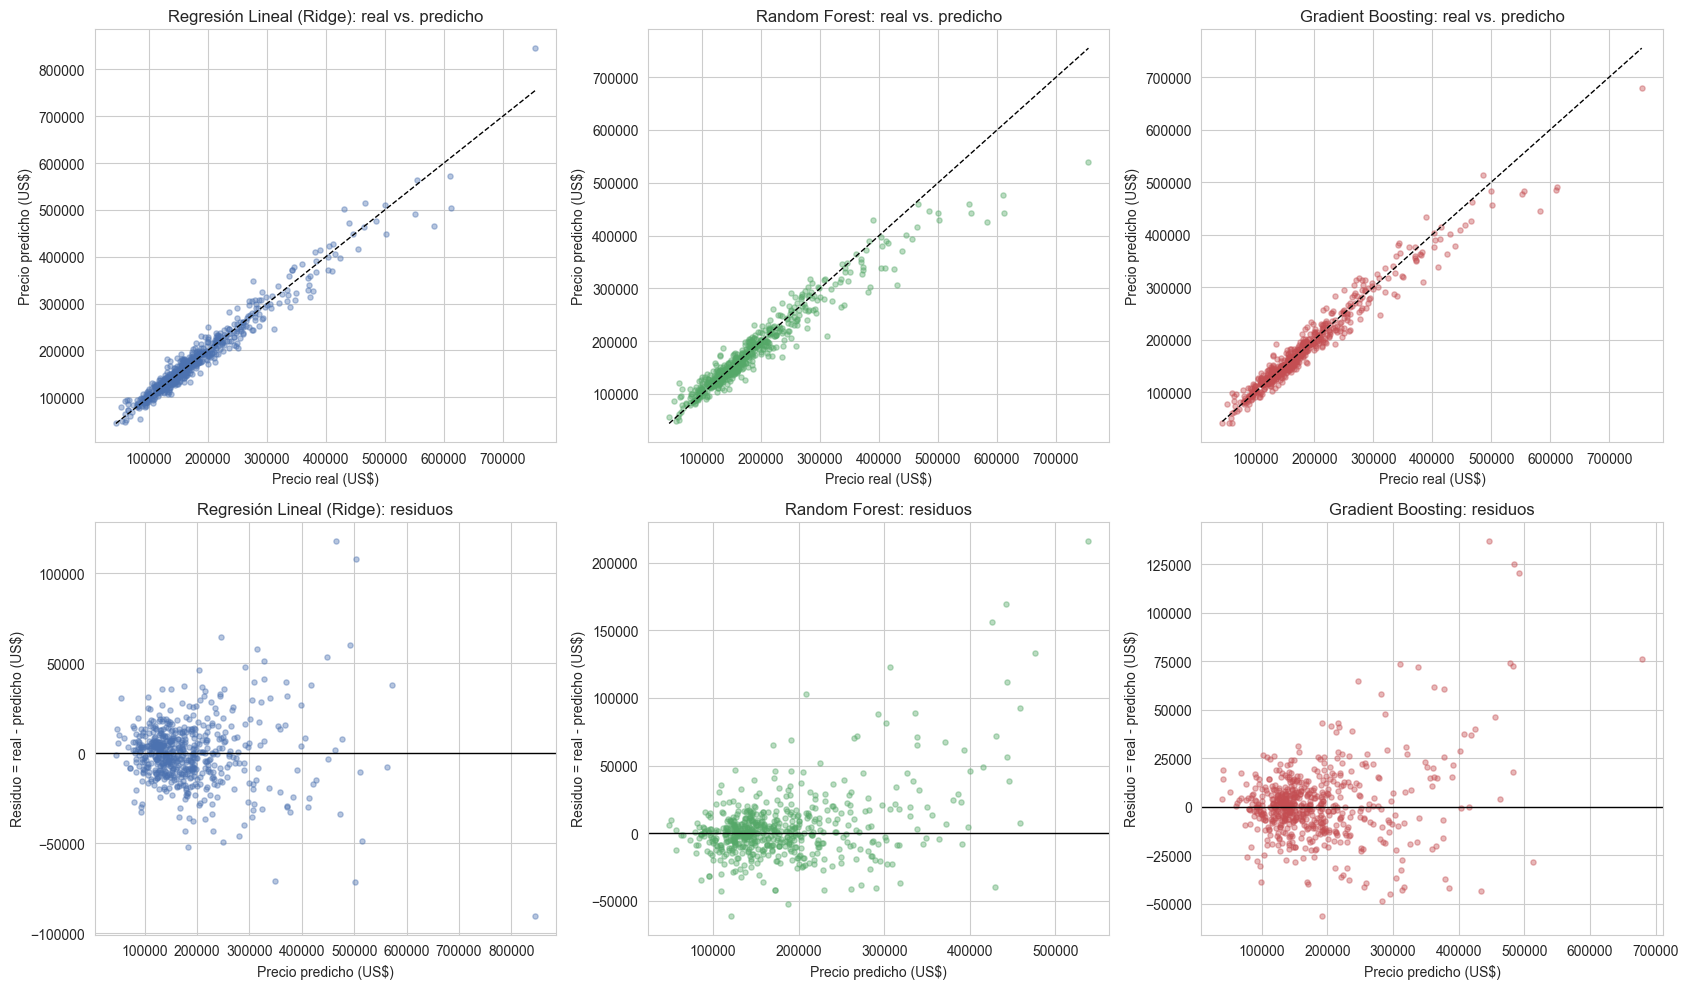

In [35]:
# Precio real vs. precio predicho y análisis de residuos (en US$) en el conjunto de prueba
y_real_usd = np.expm1(y_test)
fig, axes = plt.subplots(2, 3, figsize=(17, 10))
for j, n in enumerate(modelos_finales):
    y_pred_usd = np.expm1(mejores[n].predict(X_test))
    ax = axes[0, j]
    ax.scatter(y_real_usd, y_pred_usd, alpha=0.4, s=14, color=colores[j])
    lim = [y_real_usd.min(), y_real_usd.max()]
    ax.plot(lim, lim, "k--", linewidth=1)
    ax.set_title(f"{etiquetas[n]}: real vs. predicho")
    ax.set_xlabel("Precio real (US$)"); ax.set_ylabel("Precio predicho (US$)")
    ax = axes[1, j]
    ax.scatter(y_pred_usd, y_real_usd - y_pred_usd, alpha=0.4, s=14, color=colores[j])
    ax.axhline(0, color="black", linewidth=1)
    ax.set_title(f"{etiquetas[n]}: residuos")
    ax.set_xlabel("Precio predicho (US$)"); ax.set_ylabel("Residuo = real - predicho (US$)")
plt.tight_layout()
plt.savefig("../images/real_vs_predicho_residuos.png", dpi=120)
plt.show()

### 18.4 Selección del modelo final

**Regla de selección:** entre los modelos que cumplan los 4 umbrales de la sección 6, se elige el de **menor RMSE** en el conjunto de prueba, la métrica que más penaliza los errores grandes de tasación.


In [36]:
# Selección del modelo final: se cumple el criterio de salida y, entre los que lo cumplen, se elige el de menor RMSE
candidatos = [n for n in modelos_finales if all(cumple(resultados[n][m], *umbrales[m]) for m in umbrales)]
pool = candidatos if candidatos else modelos_finales
modelo_final = min(pool, key=lambda n: resultados[n]["RMSE"])
print(f"Modelos que cumplen los 4 umbrales: {[etiquetas[n] for n in candidatos] if candidatos else 'ninguno'}")
print(f"Modelo final seleccionado: {etiquetas[modelo_final]}")
print(f"Hiperparámetros: {cv_info[modelo_final]['mejores_params']}")

Modelos que cumplen los 4 umbrales: ['Regresión Lineal (Ridge)', 'Random Forest', 'Gradient Boosting']
Modelo final seleccionado: Regresión Lineal (Ridge)
Hiperparámetros: {'model__alpha': 30}


### 18.5 Variables más influyentes del modelo final

En un modelo lineal, el signo del coeficiente indica si la variable sube o baja el precio. Como el objetivo está en logaritmo, un coeficiente `b` equivale a un cambio aproximado de `(e^b − 1)` en el precio. Las variables numéricas están estandarizadas (el coeficiente es por cada **1 desviación estándar**); las categóricas son *dummies* (0/1).


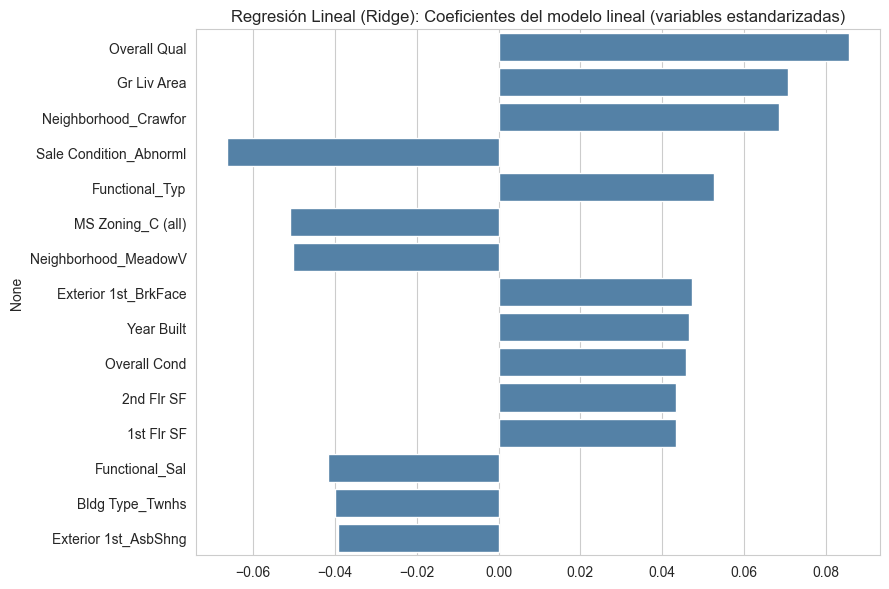

Overall Qual              0.0857
Gr Liv Area               0.0708
Neighborhood_Crawfor      0.0685
Sale Condition_Abnorml   -0.0663
Functional_Typ            0.0527
MS Zoning_C (all)        -0.0509
Neighborhood_MeadowV     -0.0504
Exterior 1st_BrkFace      0.0472
Year Built                0.0467
Overall Cond              0.0458
2nd Flr SF                0.0433
1st Flr SF                0.0433
Functional_Sal           -0.0418
Bldg Type_Twnhs          -0.0401
Exterior 1st_AsbShng     -0.0394
dtype: float64

In [37]:
# Variables más influyentes del modelo seleccionado
pipe_final = mejores[modelo_final]
nombres = pipe_final.named_steps["prep"].get_feature_names_out()
est = pipe_final.named_steps["model"]
if hasattr(est, "feature_importances_"):
    imp = pd.Series(est.feature_importances_, index=nombres)
    titulo = "Importancia de variables (reducción de impureza)"
else:
    imp = pd.Series(est.coef_, index=nombres)
    titulo = "Coeficientes del modelo lineal (variables estandarizadas)"
imp.index = [i.replace("num__", "").replace("cat__", "") for i in imp.index]
top = imp.reindex(imp.abs().sort_values(ascending=False).head(15).index)

plt.figure(figsize=(9, 6))
sns.barplot(x=top.values, y=top.index, color="steelblue")
plt.title(f"{etiquetas[modelo_final]}: {titulo}")
plt.tight_layout()
plt.savefig("../images/importancia_variables.png", dpi=120)
plt.show()
top.round(4)

### 18.6 Desempeño por barrio (mitigación de sesgo comprometida en la sección 10)

La Evaluación 1 identificó que `Neighborhood` puede actuar como *proxy* socioeconómico y comprometió medir el error de forma **desagregada por barrio**. Se excluyen del gráfico los barrios con menos de 8 ventas en el conjunto de prueba, porque su error promedio no es estable.


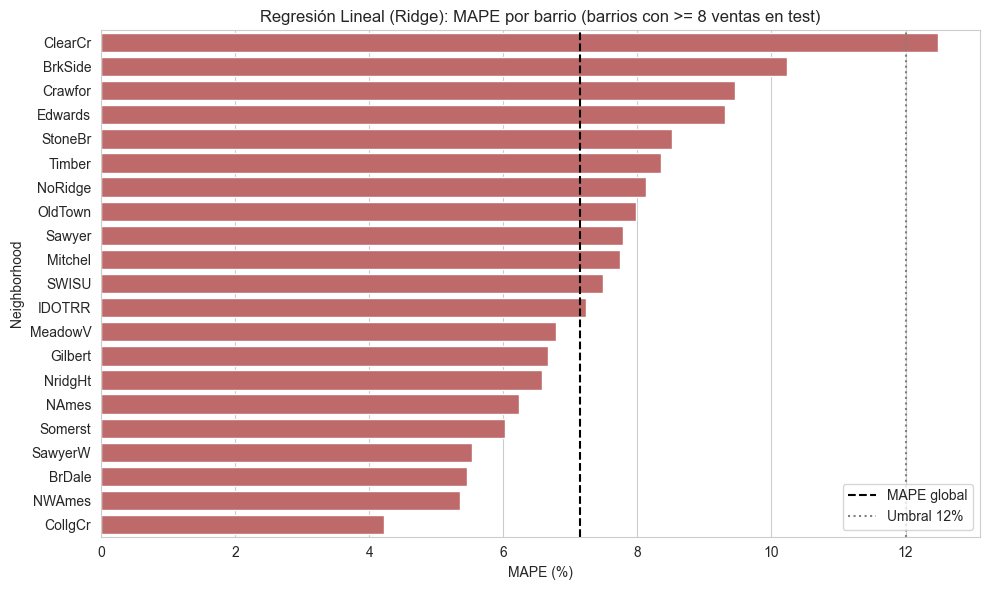

Barrios con >= 8 ventas en test: 21 de 26


,n_test,MAE,MAPE
Neighborhood,,,
ClearCr,10,22845.0,12.5
BrkSide,25,10065.1,10.2
Crawfor,16,20551.7,9.5
Edwards,45,9854.1,9.3
StoneBr,13,25915.9,8.5
Timber,14,22059.3,8.4
NoRidge,13,32458.4,8.1
OldTown,43,8673.1,8.0
Sawyer,25,10556.8,7.8


In [38]:
# Desempeño desagregado por barrio (mitigación comprometida en la sección 10 - Análisis de Sesgos)
y_pred_final = np.expm1(pipe_final.predict(X_test))
err = pd.DataFrame({
    "Neighborhood": X_test["Neighborhood"].values,
    "real": y_real_usd.values,
    "pred": y_pred_final,
})
err["error_abs"] = (err["real"] - err["pred"]).abs()
err["error_pct"] = err["error_abs"] / err["real"] * 100

por_barrio = err.groupby("Neighborhood").agg(n_test=("real", "size"), MAE=("error_abs", "mean"),
                                              MAPE=("error_pct", "mean")).sort_values("MAPE", ascending=False)
por_barrio_ok = por_barrio[por_barrio["n_test"] >= 8]   # se excluyen barrios con muy pocas ventas en test

plt.figure(figsize=(10, 6))
sns.barplot(x=por_barrio_ok["MAPE"], y=por_barrio_ok.index, color="indianred")
plt.axvline(resultados[modelo_final]["MAPE"], color="black", linestyle="--", label="MAPE global")
plt.axvline(umbrales["MAPE"][1], color="gray", linestyle=":", label="Umbral 12%")
plt.xlabel("MAPE (%)"); plt.title(f"{etiquetas[modelo_final]}: MAPE por barrio (barrios con >= 8 ventas en test)")
plt.legend(); plt.tight_layout()
plt.savefig("../images/error_por_barrio.png", dpi=120)
plt.show()
print(f"Barrios con >= 8 ventas en test: {len(por_barrio_ok)} de {len(por_barrio)}")
por_barrio_ok.round(1)

### 18.7 Desempeño por tramo de precio

Se divide el conjunto de prueba en 4 tramos de igual tamaño según el precio real.


In [39]:
# Error por tramo de precio (¿el modelo falla más en viviendas baratas o caras?)
err["tramo"] = pd.qcut(err["real"], 4, labels=["Q1 (más baratas)", "Q2", "Q3", "Q4 (más caras)"])
por_tramo = err.groupby("tramo", observed=True).agg(n=("real", "size"), precio_medio=("real", "mean"),
                                                    MAE=("error_abs", "mean"), MAPE=("error_pct", "mean"))
por_tramo.round(1)

,n,precio_medio,MAE,MAPE
tramo,,,,
Q1 (más baratas),147,104119.5,8435.4,8.9
Q2,149,143278.0,9882.3,6.9
Q3,143,182030.0,11435.3,6.3
Q4 (más caras),147,303152.5,20549.6,6.5


### 18.8 Guardado del modelo final (fase de despliegue de CRISP-DM)

Se guarda el **pipeline completo** (preprocesamiento + modelo), de modo que cualquier persona pueda predecir directamente a partir de las columnas originales de una vivienda, sin repetir la preparación a mano.


In [40]:
# Guardado del modelo final (pipeline completo: preprocesamiento + estimador) y de la tabla de resultados
joblib.dump(pipe_final, "../models/modelo_final_housing.pkl")
tabla.to_csv("../data/resultados_modelos.csv")
print("Modelo final y tabla de resultados guardados en ../models y ../data")

# Prueba de reproducibilidad: cargar el modelo guardado y predecir una vivienda del conjunto de prueba
modelo_cargado = joblib.load("../models/modelo_final_housing.pkl")
ejemplo = X_test.iloc[[0]]
print(f"Precio predicho: US$ {np.expm1(modelo_cargado.predict(ejemplo))[0]:,.0f} | precio real: US$ {y_real_usd.iloc[0]:,.0f}")

Modelo final y tabla de resultados guardados en ../models y ../data
Precio predicho: US$ 313,075 | precio real: US$ 298,236


<a id="19"></a>
## 19. Implementación del modelo no supervisado: segmentación del mercado (IE7)

### 19.1 Justificación de la aplicación al problema de negocio

Los modelos supervisados responden *«¿cuánto vale esta vivienda?»*. El aprendizaje no supervisado permite responder otra pregunta que también le importa a una inmobiliaria o portal de tasación: **¿qué tipos de vivienda existen en el mercado y se comportan igual?** Agrupar las viviendas por sus características físicas (sin mirar el precio) sirve para:

1. **Entender la estructura del mercado** y comunicar a los agentes con qué tipo de propiedad están tratando.
2. **Validar los patrones del EDA:** si los grupos formados solo con características físicas terminan con precios claramente distintos, el precio depende de verdad de esas características.
3. **Auditar el modelo supervisado por segmento**, complementando el análisis por barrio de la Evaluación 1: detectar tipos de vivienda donde el error es mayor.

**Variables y preprocesamiento:** se usan las variables numéricas de mayor correlación con el precio identificadas en el EDA (sección 8.4), estandarizadas, **sin** `SalePrice` y **sin** `Garage Yr Blt` (ver sección 13).


In [41]:
# Variables para la segmentación: las variables numéricas más correlacionadas con el precio (EDA, sección 8.4)
# Se excluye SalePrice a propósito: los segmentos se construyen solo con características físicas de la vivienda.
# Se excluye también Garage Yr Blt: en la preparación (sección 9.2) las viviendas sin garage quedaron con valor 0,
# un marcador que no es un año real y que distorsionaría las distancias del K-Means.
vars_cluster = [v for v in top_corr if v != "Garage Yr Blt"]
X_seg = df_prep[vars_cluster].copy()
X_seg_scaled = StandardScaler().fit_transform(X_seg)
print("Variables usadas para segmentar:", vars_cluster)
print("Viviendas:", X_seg.shape[0])

Variables usadas para segmentar: ['Overall Qual', 'Gr Liv Area', 'Garage Cars', 'Garage Area', 'Total Bsmt SF', '1st Flr SF', 'Year Built', 'Full Bath', 'Year Remod/Add']
Viviendas: 2927


### 19.2 Elección del número de segmentos (k)

Se prueban valores de k entre 2 y 8 y se observan dos criterios: la **inercia** (método del codo: se busca el punto donde agregar grupos ya no reduce mucho la dispersión interna) y el **coeficiente de silueta** (entre −1 y 1; mide qué tan bien separado está cada punto de los otros grupos).


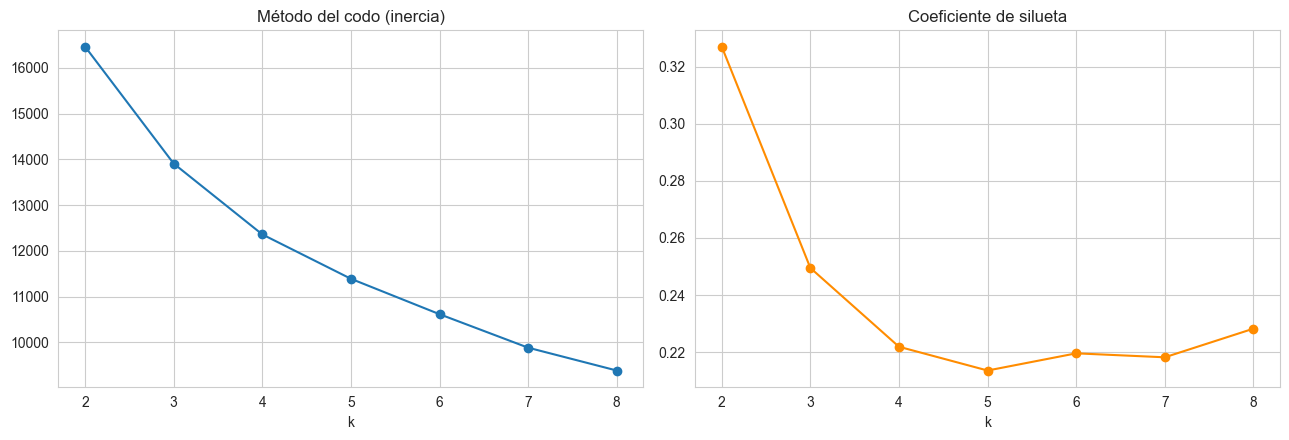

,k,inercia,silueta
0,2,16461.0,0.3270
1,3,13907.0,0.2495
2,4,12359.0,0.2219
3,5,11390.0,0.2136
4,6,10616.0,0.2196
5,7,9885.0,0.2182
6,8,9386.0,0.2282


In [42]:
# Elección del número de segmentos (k): método del codo + coeficiente de silueta
ks = range(2, 9)
inercia, silueta = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(X_seg_scaled)
    inercia.append(km.inertia_)
    silueta.append(silhouette_score(X_seg_scaled, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(list(ks), inercia, "o-"); axes[0].set_title("Método del codo (inercia)"); axes[0].set_xlabel("k")
axes[1].plot(list(ks), silueta, "o-", color="darkorange"); axes[1].set_title("Coeficiente de silueta"); axes[1].set_xlabel("k")
plt.tight_layout()
plt.savefig("../images/kmeans_codo_silueta.png", dpi=120)
plt.show()
pd.DataFrame({"k": list(ks), "inercia": np.round(inercia, 0), "silueta": np.round(silueta, 4)})

### 19.3 Resultado de K-Means

**Decisión de k = 3.** El coeficiente de silueta es máximo en k = 2 (≈ 0,33), pero esa partición solo separa en dos grandes bloques; con k = 3 la silueta baja a ≈ 0,25 y el codo no muestra un quiebre marcado, pero se obtiene una segmentación **interpretable para el negocio** (económica, intermedia y premium) con perfiles de precio bien diferenciados. Para k ≥ 4 la silueta sigue bajando sin aportar un grupo con significado nuevo. Se declara que la silueta es moderada: los tipos de vivienda forman más un **continuo** que grupos aislados.


In [43]:
# Modelo no supervisado: K-Means con el k elegido
K_ELEGIDO = 3
kmeans = KMeans(n_clusters=K_ELEGIDO, n_init=20, random_state=RANDOM_STATE).fit(X_seg_scaled)
df_seg = df_prep.copy()
df_seg["segmento"] = kmeans.labels_
print(f"k = {K_ELEGIDO} | silueta = {silhouette_score(X_seg_scaled, kmeans.labels_):.4f}")
print(df_seg["segmento"].value_counts().sort_index())

k = 3 | silueta = 0.2495
segmento
0     516
1    1334
2    1077
Name: count, dtype: int64


In [44]:
# Perfil de cada segmento (promedios de las variables de segmentación + precio, que NO se usó para formar los segmentos)
perfil = df_seg.groupby("segmento").agg(
    n=("SalePrice", "size"),
    precio_mediano=("SalePrice", "median"),
    **{v: (v, "mean") for v in vars_cluster}
).round(1)

barrios_top = df_seg.groupby("segmento")["Neighborhood"].agg(
    lambda s: ", ".join(f"{b} ({p:.0f}%)" for b, p in (s.value_counts(normalize=True).head(3) * 100).items())
)
perfil["barrios_principales"] = barrios_top
perfil

,n,precio_mediano,Overall Qual,Gr Liv Area,Garage Cars,Garage Area,Total Bsmt SF,1st Flr SF,Year Built,Full Bath,Year Remod/Add,barrios_principales
segmento,,,,,,,,,,,,
0,516,287000.0,7.9,2064.4,2.7,739.0,1617.5,1676.9,1996.4,2.1,2000.0,"NridgHt (25%), Somerst (13%), CollgCr (12%)"
1,1334,128000.0,5.1,1208.7,1.2,332.5,842.5,970.7,1948.5,1.1,1970.2,"NAmes (26%), OldTown (16%), Edwards (11%)"
2,1077,185000.0,6.5,1579.4,2.0,516.7,1028.1,1136.8,1987.5,1.9,1994.1,"CollgCr (15%), Gilbert (14%), Somerst (10%)"


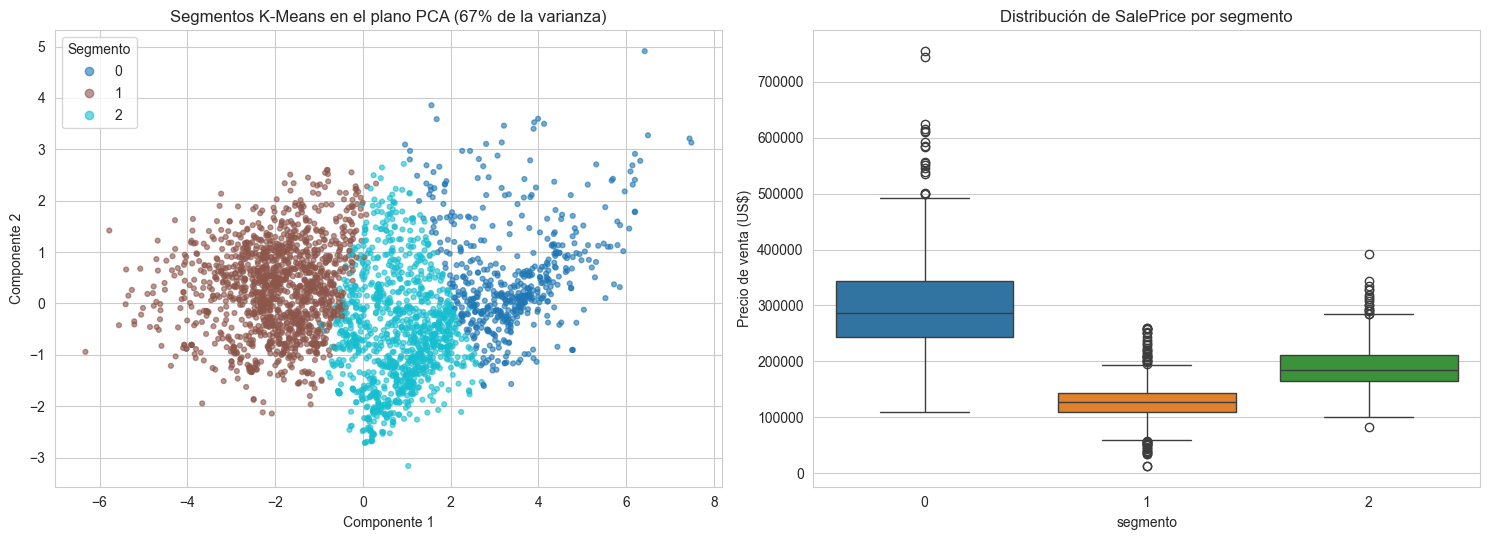

In [45]:
# Visualización de los segmentos en 2 dimensiones (PCA) y distribución del precio por segmento
pca = PCA(n_components=2, random_state=RANDOM_STATE)
Z = pca.fit_transform(X_seg_scaled)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sc = axes[0].scatter(Z[:, 0], Z[:, 1], c=df_seg["segmento"], cmap="tab10", alpha=0.6, s=12)
axes[0].set_title(f"Segmentos K-Means en el plano PCA ({pca.explained_variance_ratio_.sum()*100:.0f}% de la varianza)")
axes[0].set_xlabel("Componente 1"); axes[0].set_ylabel("Componente 2")
axes[0].legend(*sc.legend_elements(), title="Segmento")

sns.boxplot(data=df_seg, x="segmento", y="SalePrice", ax=axes[1], palette="tab10")
axes[1].set_title("Distribución de SalePrice por segmento")
axes[1].set_ylabel("Precio de venta (US$)")
plt.tight_layout()
plt.savefig("../images/kmeans_segmentos.png", dpi=120)
plt.show()

### 19.4 Cruce con el modelo supervisado

¿El modelo final rinde igual en todos los segmentos? Se calcula el error del modelo final solo con las viviendas del conjunto de prueba que pertenecen a cada segmento.


In [46]:
# Cruce con el modelo supervisado: desempeño del modelo final en cada segmento (solo viviendas del conjunto de prueba)
err_seg = err.copy()
err_seg["segmento"] = df_seg.loc[X_test.index, "segmento"].values
por_segmento = err_seg.groupby("segmento").agg(n_test=("real", "size"), precio_medio=("real", "mean"),
                                               MAE=("error_abs", "mean"), MAPE=("error_pct", "mean"))
por_segmento.round(1)

,n_test,precio_medio,MAE,MAPE
segmento,,,,
0,107,324165.7,22302.3,6.6
1,274,125944.5,9001.8,7.7
2,205,185625.2,12271.5,6.7


### 19.5 Interpretación de los segmentos

Los tres segmentos se formaron **sin usar el precio**, y aun así quedan con precios medianos claramente distintos. Eso valida que las características físicas identificadas en el EDA realmente ordenan el mercado.

| Segmento | Viviendas | Precio mediano | Perfil | Barrios más frecuentes |
|---|---|---|---|---|
| **Premium** | 516 (≈ 18%) | US$ 287.000 | Calidad ≈ 7,9 · ≈ 2.060 pies² habitables · garage para ≈ 2,7 autos · construcción reciente (≈ 1996) | `NridgHt`, `Somerst`, `CollgCr` |
| **Intermedio** | 1.077 (≈ 37%) | US$ 185.000 | Calidad ≈ 6,5 · ≈ 1.580 pies² · garage para 2 autos · construcción ≈ 1987 | `CollgCr`, `Gilbert`, `Somerst` |
| **Económico** | 1.334 (≈ 46%) | US$ 128.000 | Calidad ≈ 5,1 · ≈ 1.210 pies² · garage más pequeño · construcción ≈ 1948 y remodelaciones más antiguas | `NAmes`, `OldTown`, `Edwards` |

- **Patrón relevante:** el mercado de Ames se divide en tres tipos de vivienda según **calidad, tamaño, equipamiento (garage, sótano, baños) y antigüedad**. La mayor parte de las ventas (≈ 46%) corresponde al segmento económico.
- **Conexión con la ubicación:** los segmentos se asocian a barrios distintos aunque `Neighborhood` no se usó para formarlos, lo que refuerza que la ubicación y el tipo de vivienda van de la mano (hallazgo ya visto en la sección 8.5).
- **Límite:** los grupos se solapan (silueta ≈ 0,25), así que una vivienda cercana a la frontera entre dos segmentos puede pertenecer a cualquiera de ellos.


<a id="20"></a>
## 20. Interpretación del desempeño y recomendaciones de negocio (IE8)

### 20.1 ¿Qué dicen las métricas?

| Métrica | Umbral (sección 6) | Regresión Lineal (Ridge) | Random Forest | Gradient Boosting |
|---|---|---|---|---|
| **R²** | ≥ 0,80 | **0,959** | 0,921 | 0,953 |
| **RMSE** | ≤ US$ 30.000 | **US$ 18.170** | US$ 25.293 | US$ 19.403 |
| **MAE** | ≤ US$ 20.000 | US$ 12.574 | US$ 14.724 | **US$ 12.508** |
| **MAPE** | ≤ 12% | 7,15% | 7,88% | **6,87%** |

- **Los tres modelos superan los cuatro umbrales**, por lo que el criterio de salida de la Evaluación 1 se cumple en la primera iteración y no fue necesario volver a etapas anteriores.
- **Ridge explica ≈ 96% de la variabilidad del precio** en viviendas que nunca vio. Su RMSE (US$ 18.170) está ≈ 39% por debajo del límite y equivale a ≈ 11% del precio mediano (US$ 160.000); su MAE (US$ 12.574) está ≈ 37% por debajo del límite. En lenguaje de negocio: **la predicción típica se equivoca en torno a US$ 12.600, es decir, ≈ 7% del valor de la vivienda**.
- **¿Por qué Ridge y no Gradient Boosting?** Las diferencias entre ambos son pequeñas: Gradient Boosting tiene un MAE y un MAPE marginalmente menores, pero Ridge logra **menor RMSE en el conjunto de prueba y también menor RMSE en validación cruzada** (0,1229 frente a 0,1242 en escala logarítmica), de modo que ambas fuentes de evidencia coinciden. Además, Gradient Boosting muestra un ajuste mucho más holgado en entrenamiento (R² 0,987 frente a 0,953 en prueba), es decir, **mayor sobreajuste**, mientras que Ridge se comporta de forma estable (R² entrenamiento 0,944). Y Ridge es el modelo **más explicable**, que era justamente la prioridad de negocio planteada en la Evaluación 1 (tasadores que deben justificar el precio a un cliente).
- **Random Forest** es el de menor desempeño: cumple los umbrales pero con el menor margen, y su R² en entrenamiento (0,976) frente al de prueba (0,921) muestra sobreajuste.
- **Una conclusión que conviene tener clara en la defensa:** en este dataset, después de la transformación logarítmica y la preparación de la Evaluación 1, **el modelo simple y regularizado compite de igual a igual con el más complejo**. Eso respalda la decisión de la Evaluación 1 de incluir la regresión lineal como línea base seria, no como un simple trámite.

### 20.2 ¿Dónde se equivoca más el modelo?

- **Por tramo de precio:** el error **absoluto** crece con el precio (MAE ≈ US$ 20.550 en el cuarto más caro frente a ≈ US$ 8.400 en el más barato), pero el error **relativo** es mayor en las viviendas baratas (MAPE ≈ 8,9% frente a ≈ 6,5% en las caras). Un error de US$ 8.000 pesa más en una casa de US$ 100.000 que uno de US$ 20.000 en una de US$ 300.000.
- **Por barrio:** el MAPE va de ≈ 4% (`CollgCr`) a ≈ 12,5% (`ClearCr`). **`ClearCr` supera el umbral de 12%**, aunque con solo 10 ventas en prueba, por lo que es una señal a vigilar y no una conclusión firme. `NoRidge` (barrio de viviendas caras) muestra el mayor error absoluto (≈ US$ 32.000). Esto confirma de forma empírica el riesgo planteado en la sección 10: **el desempeño no es uniforme entre barrios**, aunque ningún otro barrio con muestra suficiente supera el umbral de MAPE.
- **Por segmento (sección 19):** el modelo final se comporta de forma **bastante pareja en términos relativos** (MAPE entre ≈ 6,6% y ≈ 7,7%, todos bajo el umbral de 12%). El error absoluto sí crece con el nivel de precio: MAE ≈ US$ 22.300 en el segmento premium, ≈ US$ 12.300 en el intermedio y ≈ US$ 9.000 en el económico. El segmento económico tiene el mayor error relativo (≈ 7,7%), coherente con lo visto por tramo de precio.

### 20.3 ¿Qué variables mueven el precio?

El modelo lineal permite una lectura directa (efecto aproximado, manteniendo lo demás constante):

- **`Overall Qual`:** subir 1 desviación estándar en calidad general se asocia a **≈ +9% de precio**. Es la variable más influyente.
- **`Gr Liv Area`:** 1 desviación estándar más de superficie habitable se asocia a **≈ +7%**.
- **Ubicación:** estar en `Crawfor` suma ≈ +7%; estar en `MeadowV` resta ≈ 5%.
- **`Sale Condition_Abnorml`** (ventas anormales, p. ej. ejecuciones o ventas apremiadas): se asocia a **≈ −6%**. Es un hallazgo de negocio: el precio de una venta forzada **no es el precio de mercado** de la propiedad.
- **Advertencia de interpretación:** variables muy correlacionadas entre sí (`1st Flr SF`, `2nd Flr SF`, `Gr Liv Area`) se reparten el efecto, por lo que sus coeficientes individuales no deben leerse de forma aislada. Además, estos coeficientes describen **asociación, no causalidad**: renovar una cocina no necesariamente produce el aumento que insinúa el coeficiente de calidad.

### 20.4 Recomendaciones para el negocio

1. **Usar el modelo como precio de referencia inicial** para tasadores y agentes, no como tasación final. Entrega una respuesta inmediata y consistente, que ataca los problemas de inconsistencia y lentitud de la sección 1.
2. **Mostrar siempre un rango y no un número único.** Con un error típico (MAE) de ≈ US$ 12.600, una presentación como «US$ X ± 12.600» es más honesta que un precio exacto. Para viviendas del cuarto de mayor precio, el rango debería ser más amplio (≈ ± US$ 20.000).
3. **Derivar a revisión humana** las propiedades de alto valor, las de barrios con mayor error (`ClearCr`, `BrkSide`, `NoRidge`) y las ventas de condición anormal.
4. **Usar los segmentos** para ordenar la cartera de propiedades y para adaptar el discurso comercial y el nivel de revisión según el tipo de vivienda.
5. **No usar el modelo para decisiones con impacto directo en personas** (créditos hipotecarios, seguros) sin validación adicional, tal como se advirtió en las secciones 10 y 11.
6. **Respetar el alcance:** el modelo se entrenó con ventas de **Ames, Iowa, entre 2006 y 2010**. No debe aplicarse a otras ciudades ni al mercado chileno sin reentrenar con datos locales.
7. **Monitorear y reentrenar:** vigilar periódicamente el error global y por barrio, y reentrenar cuando el mercado cambie (*data drift*).


<a id="21"></a>
## 21. Conclusiones finales y limitaciones

### Conclusiones de la Evaluación 2

1. Se aplicó **CRISP-DM** de punta a punta, y las decisiones de la Evaluación 1 (algoritmos, métricas, umbrales, preparación, división de datos) se ejecutaron sin cambios, lo que da trazabilidad completa al proyecto.
2. Se implementaron y compararon **3 modelos supervisados** (Ridge/Lasso, Random Forest y Gradient Boosting), todos con el mismo pipeline y ajuste de hiperparámetros por validación cruzada. **Los tres cumplen los 4 umbrales de aceptación.**
3. El **modelo final es la Regresión Lineal con regularización Ridge** (R² ≈ 0,96; RMSE ≈ US$ 18.200; MAE ≈ US$ 12.600; MAPE ≈ 7,2%), elegido por su menor RMSE (en prueba y en validación cruzada), su menor sobreajuste y su interpretabilidad.
4. Las variables que más pesan en el precio son la **calidad general, la superficie habitable y el barrio**, en línea con lo hallado en el EDA; las ventas anormales se asocian a precios menores.
5. La segmentación con **K-Means (k = 3)** identificó tipos de vivienda diferenciables solo con características físicas y con precios claramente distintos, y permitió auditar el modelo por segmento.
6. Se cumplió el compromiso de la Evaluación 1 de revisar el error **por barrio**: el desempeño no es uniforme, y hay barrios que requieren supervisión humana.

### Limitaciones (declararlas es parte de una buena defensa)

- **Búsqueda de hiperparámetros acotada:** se usaron cuadrículas pequeñas y validación cruzada de 3 particiones para que el notebook se ejecute en minutos. Una búsqueda más amplia podría mejorar sobre todo a Random Forest y Gradient Boosting.
- **Una sola partición train/test:** los resultados dependen de la semilla 42; con 586 viviendas de prueba, diferencias pequeñas entre modelos (como Ridge vs. Gradient Boosting) no deben sobreinterpretarse. La validación cruzada apunta en la misma dirección, lo que da más confianza.
- **División aleatoria, no temporal:** el dataset cubre 2006-2010, por lo que un modelo en producción se enfrentaría a precios futuros; una validación por fecha de venta sería más exigente.
- **Fuga de información menor en la Parte 1:** la mediana de `Lot Frontage` por barrio y la eliminación de outliers se calcularon antes de dividir en train/test. El efecto es mínimo, pero es un punto que se puede mencionar.
- **Decisiones heredadas que podrían revisarse:** `MS SubClass` es un código de categoría que quedó tratado como numérico, y `Garage Yr Blt` usa `0` para «sin garage». No se modificaron para respetar las decisiones de la Evaluación 1.
- **Retransformación del logaritmo:** `expm1` de la predicción del logaritmo estima la mediana condicional, lo que puede subestimar levemente el precio promedio.
- **Muestras pequeñas por barrio:** el error por barrio se calcula con pocas ventas (entre 8 y 91 en prueba); los barrios con menos de 8 se omitieron.
- **Segmentos solapados:** la silueta moderada indica que las fronteras entre segmentos son difusas.

### Posibles mejoras
Validación cruzada repetida con búsqueda más amplia; probar XGBoost o LightGBM; modelos separados por segmento; interpretabilidad con SHAP; intervalos de predicción en lugar de predicciones puntuales; y validación temporal.


### 22 Notas de reproducibilidad

- Si se vuelven a leer los archivos `X_train.csv` / `X_test.csv`, usar `pd.read_csv(..., keep_default_na=False)`: de lo contrario pandas interpreta el texto `"None"` y `"NA"` como valores nulos y se perdería la distinción entre «sin garage» y «dato faltante» hecha en la sección 9.2. Dentro de este notebook el problema no existe, porque se trabaja con los objetos ya en memoria.
- Todos los procesos aleatorios usan `random_state=42`.